# Build an LLM from Scratch — Research-Based Assessment

This notebook implements the **whole assignment** end-to-end:

| Phase | What happens |
|---|---|
| 0 | Setup: GPU check, Google Drive, global settings |
| 1 | Dataset: Project Gutenberg book(s) → GPT-2 tokens → train/val split |
| 2 | GPT model with **ablation switches** (`use_norm`, `use_shortcut`, `use_ffn`) |
| 3 | Sanity checks (initial loss ≈ ln(50257), overfit one batch) |
| 4 | Training harness: logging, checkpoint/resume, text samples, results saved to Drive |
| 5 | Baseline training |
| 6 | Experiment 1 — epochs × learning rate |
| 7 | Experiment 2 — number of transformer layers (1, 3, 5, 7, 12) |
| 8 | Experiment 3 — number of attention heads (1, 2, 4, 8) |
| 9 | Experiment 4 — ablations (no LayerNorm / no shortcut / no FFN) |
| 10 | Master results table, generated samples, download figures for Overleaf |

### How to use
1. **Runtime → Change runtime type → T4 GPU** (or better).
2. First run with `QUICK_MODE = True` (Phase 0) → *Runtime → Run all*. A tiny model runs every cell in a few minutes, which proves the pipeline works.
3. Set `QUICK_MODE = False` → *Run all* again for the real experiments.
4. **Every finished run is saved as JSON to Google Drive.** If Colab disconnects, just re-run all cells: finished runs load instantly from Drive and an interrupted run resumes from its last checkpoint.

**Approximate time, full mode** (one book ≈ 160k tokens): a Colab T4 needs about 3 h in total, and a local GTX 1650 needs about 6–7 h. Most of it is Experiment 1's three 500-epoch runs; set `EXP1_MAX_EPOCHS = 200` to roughly halve that.

**Running locally instead of Colab** (e.g. in VS Code/Jupyter): this works unchanged. Results go to `./LLM_Scratch_Assignment`. The GPU, precision and batch size are detected automatically. You need a CUDA build of PyTorch plus `tiktoken pandas matplotlib`.

## Phase 0 — Setup

In [1]:
!pip install -q tiktoken

import os, re, json, math, time, random, contextlib, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import tiktoken

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. In Colab: Runtime -> Change runtime type -> T4 GPU")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

PyTorch 2.11.0+cu130 | device: cuda
GPU: Tesla T4


In [2]:
# Results go to Google Drive so a Colab disconnect never loses finished runs.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/LLM_Scratch_Assignment"
    IN_COLAB = True
except ImportError:
    SAVE_DIR = "./LLM_Scratch_Assignment"
    IN_COLAB = False

RUNS_DIR = os.path.join(SAVE_DIR, "runs")      # one JSON per finished run (+ a .pt checkpoint while running)
FIG_DIR  = os.path.join(SAVE_DIR, "figures")   # PNG + PDF of every plot, ready for Overleaf
TAB_DIR  = os.path.join(SAVE_DIR, "tables")    # CSV + LaTeX tables, generated text samples
DATA_DIR = os.path.join(SAVE_DIR, "data")      # downloaded books
for d in (RUNS_DIR, FIG_DIR, TAB_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)
print("Saving everything to:", SAVE_DIR)

Mounted at /content/drive
Saving everything to: /content/drive/MyDrive/LLM_Scratch_Assignment


### Global settings
Everything that is held **constant across experiments** lives here. A controlled experiment changes one thing at a time — so the seed, batch size, optimizer, data split and evaluation protocol never change.

The model is a **scaled-down GPT-2** (the 124M GPT-2 is too expensive to train ~20 times on a free GPU). State this choice in your report.

In [3]:
# True  = tiny smoke test of the WHOLE notebook (a few minutes). Do this first.
# False = the real experiments for your report.
QUICK_MODE = False

SEED = 123

# Hardware-dependent settings, chosen automatically (Colab T4 -> fp16 + batch 16; GTX 1650 -> fp32 + batch 8).
# fp16 is only fast on GPUs with tensor cores; GTX 16-series cards are ~4x SLOWER in fp16 than fp32.
# Batch 16 needs ~4 GB of activations (mostly the 50,257-way output logits), so 4 GB cards use 8.
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEVICE == "cuda" else 0
USE_AMP = DEVICE == "cuda" and torch.cuda.get_device_capability(0) >= (7, 0) and "GTX" not in GPU_NAME
BATCH_SIZE = 8 if DEVICE == "cuda" and GPU_MEM_GB < 6 else 16
WEIGHT_DECAY = 0.1              # AdamW weight decay, same for every run
GRAD_CLIP = 1.0                 # gradient-norm clipping, same for every run (None = off)
EVAL_TRAIN_BATCHES = 10         # training loss is measured on a fixed subset of this many batches
PROMPT = "I am sure that"       # fixed prompt for every generated sample — change it to suit your book
SAMPLE_TOKENS = 50

BASE_CFG = {
    "vocab_size": 50257,     # GPT-2 BPE tokenizer
    "context_length": 256,
    "emb_dim": 256,          # divisible by 1, 2, 4 and 8 heads
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False,
    # --- ablation switches (Experiment 4) ---
    "use_norm": True,        # LayerNorm inside every transformer block
    "use_shortcut": True,    # residual (shortcut) connections inside every transformer block
    "use_ffn": True,         # feed-forward network inside every transformer block
}

MAX_TOKENS = None            # None = use the whole corpus
if QUICK_MODE:
    BASE_CFG.update(context_length=64, emb_dim=64)
    EVAL_TRAIN_BATCHES = 3
    MAX_TOKENS = 40_000

RUN_PREFIX = "quick_" if QUICK_MODE else ""
print(f"QUICK_MODE = {QUICK_MODE} | {GPU_NAME} ({GPU_MEM_GB:.1f} GB) | fp16 AMP = {USE_AMP} | batch = {BATCH_SIZE}")
print(BASE_CFG)

QUICK_MODE = False | Tesla T4 (14.6 GB) | fp16 AMP = True | batch = 16
{'vocab_size': 50257, 'context_length': 256, 'emb_dim': 256, 'n_heads': 4, 'n_layers': 4, 'drop_rate': 0.1, 'qkv_bias': False, 'use_norm': True, 'use_shortcut': True, 'use_ffn': True}


## Phase 1 — Dataset

Pick any book(s) from [Project Gutenberg](https://www.gutenberg.org). The plain-text URL of book `<ID>` is
`https://www.gutenberg.org/cache/epub/<ID>/pg<ID>.txt`. Several books are joined into one corpus.

The Gutenberg licence header/footer, `[Illustration]` tags and indentation spaces are **removed**. Otherwise the model also learns boilerplate and wastes capacity on whitespace.

In [4]:
BOOKS = {
    "Pride and Prejudice": "https://www.gutenberg.org/cache/epub/1342/pg1342.txt",
    # "Emma":                  "https://www.gutenberg.org/cache/epub/158/pg158.txt",
    # "Sense and Sensibility": "https://www.gutenberg.org/cache/epub/161/pg161.txt",
}
UPLOAD_OWN_FILE = False   # True = upload your own .txt file(s) from your computer instead


def strip_gutenberg(text):
    """Keep only the book text: drop the licence header/footer and illustration tags, tidy whitespace."""
    start = text.find("*** START OF")
    start = text.find("\n", start) + 1 if start != -1 else 0
    end = text.find("*** END OF")
    end = end if end != -1 else len(text)
    text = text[start:end]
    text = re.sub(r"\[Illustration[^\]]*\]", "", text)        # drop [Illustration: ...] blocks
    text = "\n".join(line.strip() for line in text.splitlines())  # drop centring/indent spaces
    text = re.sub(r"\n{3,}", "\n\n", text)                        # at most one blank line
    return text.strip()


def load_corpus():
    texts = []
    if UPLOAD_OWN_FILE and IN_COLAB:
        from google.colab import files
        for name, content in files.upload().items():
            texts.append(strip_gutenberg(content.decode("utf-8", errors="ignore")))
            print(f"{name}: {len(texts[-1]):,} characters")
        return "\n\n".join(texts)
    for title, url in BOOKS.items():
        path = os.path.join(DATA_DIR, os.path.basename(url))
        if not os.path.exists(path):
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as resp, open(path, "wb") as f:
                f.write(resp.read())
        with open(path, encoding="utf-8-sig", errors="ignore") as f:
            texts.append(strip_gutenberg(f.read()))
        print(f"{title}: {len(texts[-1]):,} characters")
    return "\n\n".join(texts)


raw_text = load_corpus()
print("\n--- first 400 characters ---\n" + raw_text[:400])

Pride and Prejudice: 718,925 characters

--- first 400 characters ---
PRIDE.
and
PREJUDICE

by
Jane Austen,

with a Preface by
George Saintsbury
and
Illustrations by
Hugh Thomson

Ruskin       156. Charing
House.        Cross Road.

London
George Allen.

CHISWICK PRESS:--CHARLES WHITTINGHAM AND CO.
TOOKS COURT, CHANCERY LANE, LONDON.

PREFACE.

_Walt Whitman has somewhere a fine and just distinction between “loving
by allowance” and “loving with personal love.” This


### Tokenize, split, and build training sequences
* **Tokenizer:** GPT-2 byte-pair encoding (`tiktoken`), vocabulary 50,257.
* **Split:** first 90% of tokens → train, last 10% → validation. The validation text is chapters the model never sees, so validation loss measures *generalisation*, not memorisation.
* **Sequences:** non-overlapping windows of `context_length` tokens (stride = context length). The target is the input shifted by one token: the model learns *next-token prediction*.
* **One epoch** = one full pass over all training sequences.

In [5]:
tokenizer = tiktoken.get_encoding("gpt2")
token_ids = tokenizer.encode(raw_text, allowed_special={"<|endoftext|>"})
if MAX_TOKENS:
    token_ids = token_ids[:MAX_TOKENS]

split = int(0.9 * len(token_ids))
train_ids = torch.tensor(token_ids[:split])
val_ids = torch.tensor(token_ids[split:])


def make_sequences(ids, context_length, stride):
    """Sliding windows: x = ids[i : i+ctx], y = ids[i+1 : i+ctx+1]."""
    n = (len(ids) - 1 - context_length) // stride + 1
    idx = torch.arange(n)[:, None] * stride + torch.arange(context_length)[None, :]
    return ids[idx], ids[idx + 1]


CTX = BASE_CFG["context_length"]
X_train, Y_train = make_sequences(train_ids, CTX, stride=CTX)
X_val, Y_val = make_sequences(val_ids, CTX, stride=CTX)
X_train, Y_train, X_val, Y_val = (t.to(DEVICE) for t in (X_train, Y_train, X_val, Y_val))

# fixed random subset of training sequences used to measure training loss
_g = torch.Generator().manual_seed(SEED)
_eval_idx = torch.randperm(len(X_train), generator=_g)[: EVAL_TRAIN_BATCHES * BATCH_SIZE].to(DEVICE)
X_train_eval, Y_train_eval = X_train[_eval_idx], Y_train[_eval_idx]

STEPS_PER_EPOCH = math.ceil(len(X_train) / BATCH_SIZE)
dataset_stats = {
    "books": list(BOOKS) if not UPLOAD_OWN_FILE else "uploaded",
    "characters": len(raw_text),
    "total_tokens": len(token_ids),
    "train_tokens": len(train_ids),
    "val_tokens": len(val_ids),
    "context_length": CTX,
    "train_sequences": len(X_train),
    "val_sequences": len(X_val),
    "batch_size": BATCH_SIZE,
    "steps_per_epoch": STEPS_PER_EPOCH,
}
with open(os.path.join(TAB_DIR, "dataset_stats.json"), "w") as f:
    json.dump(dataset_stats, f, indent=2)
for k, v in dataset_stats.items():
    print(f"{k:>16}: {v:,}" if isinstance(v, int) else f"{k:>16}: {v}")

print("\nExample input :", repr(tokenizer.decode(X_train[0, :20].tolist())))
print("Example target:", repr(tokenizer.decode(Y_train[0, :20].tolist())))

           books: ['Pride and Prejudice']
      characters: 718,925
    total_tokens: 186,785
    train_tokens: 168,106
      val_tokens: 18,679
  context_length: 256
 train_sequences: 656
   val_sequences: 72
      batch_size: 16
 steps_per_epoch: 41

Example input : 'PRIDE.\nand\nPREJUDICE\n\nby\nJane Austen,\n\n'
Example target: 'IDE.\nand\nPREJUDICE\n\nby\nJane Austen,\n\nwith'


## Phase 2 — GPT model with ablation switches

A pre-norm GPT block computes

$$x \leftarrow x + \text{Attention}(\text{LayerNorm}(x)) \qquad x \leftarrow x + \text{FFN}(\text{LayerNorm}(x))$$

The three switches remove exactly one ingredient **inside every block**:

| Switch | Effect |
|---|---|
| `use_norm=False` | `LayerNorm` → identity |
| `use_shortcut=False` | `x + f(x)` → `f(x)` (no residual path) |
| `use_ffn=False` | the FFN sub-layer is dropped entirely |

The final LayerNorm before the output head is kept in all runs, because the assignment asks to remove normalisation *in the transformer layers*. Mention this in your report. Pass `"final_norm": False` to remove it as well.

Attention uses PyTorch's fused `scaled_dot_product_attention`, which computes $\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_{head}}} + M_{causal}\right)V$ — the same maths as a hand-written implementation, just faster.

In [6]:
class MultiHeadAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d, h = cfg["emb_dim"], cfg["n_heads"]
        assert d % h == 0, "emb_dim must be divisible by n_heads"
        self.n_heads, self.head_dim = h, d // h
        self.qkv = nn.Linear(d, 3 * d, bias=cfg["qkv_bias"])
        self.out_proj = nn.Linear(d, d)
        self.dropout = cfg["drop_rate"]

    def forward(self, x):
        b, t, d = x.shape
        # (b, t, 3d) -> 3 x (b, heads, t, head_dim)
        q, k, v = self.qkv(x).view(b, t, 3, self.n_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        # causal mask: token i may only attend to tokens <= i
        out = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0)
        return self.out_proj(out.transpose(1, 2).reshape(b, t, d))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["emb_dim"]
        self.net = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["emb_dim"]
        self.att = MultiHeadAttention(cfg)
        self.ff = FeedForward(cfg) if cfg["use_ffn"] else None
        self.norm1 = nn.LayerNorm(d) if cfg["use_norm"] else nn.Identity()
        self.norm2 = nn.LayerNorm(d) if cfg["use_norm"] and cfg["use_ffn"] else nn.Identity()
        self.drop = nn.Dropout(cfg["drop_rate"])
        self.use_shortcut = cfg["use_shortcut"]

    def forward(self, x):
        h = self.drop(self.att(self.norm1(x)))
        x = x + h if self.use_shortcut else h
        if self.ff is not None:
            h = self.drop(self.ff(self.norm2(x)))
            x = x + h if self.use_shortcut else h
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["emb_dim"]
        self.tok_emb = nn.Embedding(cfg["vocab_size"], d)
        self.pos_emb = nn.Embedding(cfg["context_length"], d)
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = nn.LayerNorm(d) if cfg.get("final_norm", True) else nn.Identity()
        self.out_head = nn.Linear(d, cfg["vocab_size"], bias=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        # GPT-2 initialisation: N(0, 0.02) weights, zero biases
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx):
        t = idx.shape[1]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(t, device=idx.device))
        x = self.blocks(self.drop_emb(x))
        return self.out_head(self.final_norm(x))   # logits: (batch, t, vocab)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    emb = sum(p.numel() for m in (model.tok_emb, model.pos_emb, model.out_head) for p in m.parameters())
    return total, total - emb   # (all, non-embedding = the transformer blocks)


# Parameter counts of every configuration used in the experiments
rows = []
variants = ([("layers", {"n_layers": L}) for L in (1, 3, 5, 7, 12)]
            + [("heads", {"n_heads": h}) for h in (1, 2, 4, 8)]
            + [("ablation", {"use_norm": False}), ("ablation", {"use_shortcut": False}), ("ablation", {"use_ffn": False})])
for group, change in [("baseline", {})] + variants:
    m = GPTModel({**BASE_CFG, **change})
    total, non_emb = count_params(m)
    rows.append({"group": group, "change": str(change), "params_M": total / 1e6, "block_params_M": non_emb / 1e6})
    del m
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nNote: most parameters sit in the token embedding and output head (2 x 50257 x emb_dim).")

   group                  change  params_M  block_params_M
baseline                      {}    28.954           3.156
  layers         {'n_layers': 1}    26.587           0.790
  layers         {'n_layers': 3}    28.165           2.367
  layers         {'n_layers': 5}    29.743           3.945
  layers         {'n_layers': 7}    31.321           5.523
  layers        {'n_layers': 12}    35.266           9.468
   heads          {'n_heads': 1}    28.954           3.156
   heads          {'n_heads': 2}    28.954           3.156
   heads          {'n_heads': 4}    28.954           3.156
   heads          {'n_heads': 8}    28.954           3.156
ablation     {'use_norm': False}    28.950           3.152
ablation {'use_shortcut': False}    28.954           3.156
ablation      {'use_ffn': False}    26.849           1.052

Note: most parameters sit in the token embedding and output head (2 x 50257 x emb_dim).


### Text generation
Samples always use the **same prompt, seed, temperature (0.8) and top-k (40)**, so text from different models can be compared fairly. This is your evidence for "inference quality" in Experiment 4.

In [7]:
@torch.no_grad()
def generate_text(model, prompt=PROMPT, max_new_tokens=SAMPLE_TOKENS, temperature=0.8, top_k=40, seed=SEED):
    model.eval()
    ctx = model.pos_emb.num_embeddings
    idx = torch.tensor([tokenizer.encode(prompt)], device=DEVICE)
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    for _ in range(max_new_tokens):
        logits = model(idx[:, -ctx:])[:, -1, :].float()
        if top_k:
            kth = torch.topk(logits, top_k).values[:, [-1]]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        probs = torch.softmax(logits / temperature, dim=-1)
        idx = torch.cat([idx, torch.multinomial(probs, 1, generator=gen)], dim=1)
    model.train()
    return tokenizer.decode(idx[0].tolist())


def safe_generate(model):
    try:
        return generate_text(model)
    except RuntimeError as e:          # e.g. NaN logits from a diverged model
        return f"<generation failed: {str(e)[:80]}>"

## Phase 3 — Sanity checks (do not skip)
1. **Initial loss ≈ ln(50257) ≈ 10.82.** A random model should be uniformly unsure about every token. A loss far from this points to a bug.
2. **Overfit one batch.** A correct model + training loop can memorise 16 sequences, so loss → near 0. If it cannot, something is broken.
3. **Every ablation variant runs** and produces logits of the right shape.

In [8]:
set_seed(SEED)
model = GPTModel(BASE_CFG).to(DEVICE)
xb, yb = X_train[:BATCH_SIZE], Y_train[:BATCH_SIZE]

with torch.no_grad():
    model.eval()
    loss0 = F.cross_entropy(model(xb).flatten(0, 1), yb.flatten()).item()
print(f"1) Initial loss = {loss0:.3f}   (expected ~ ln(50257) = {math.log(50257):.3f})")

model.train()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
for step in range(1, 201):
    loss = F.cross_entropy(model(xb).flatten(0, 1), yb.flatten())
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 50 == 0:
        print(f"   overfit step {step:3d}: loss {loss.item():.3f}")
print("2) Overfit-one-batch:", "PASS" if loss.item() < 1.0 else "CHECK — loss did not go near 0")
print("   memorised text:", repr(generate_text(model, prompt=tokenizer.decode(xb[0, :5].tolist()))[:150]))
del model, opt

for change in ({"use_norm": False}, {"use_shortcut": False}, {"use_ffn": False}):
    m = GPTModel({**BASE_CFG, **change}).to(DEVICE)
    with torch.no_grad():
        out = m(xb[:2])
    print(f"3) {str(change):28s} -> logits {tuple(out.shape)}  finite={torch.isfinite(out).all().item()}")
    del m
if DEVICE == "cuda":
    torch.cuda.empty_cache()

1) Initial loss = 10.859   (expected ~ ln(50257) = 10.825)
   overfit step  50: loss 5.967
   overfit step 100: loss 4.884
   overfit step 150: loss 0.717
   overfit step 200: loss 0.042
2) Overfit-one-batch: PASS
   memorised text: 'PRIDE.\nand\nPREJUDICE\n\nby\nJane Austen,\n\nwith a Preface by\nGeorge Saintsbury\nand\nIllustrations by\nHugh Thomson\n\nRuskin       156. Charing\n'
3) {'use_norm': False}          -> logits (2, 256, 50257)  finite=True
3) {'use_shortcut': False}      -> logits (2, 256, 50257)  finite=True
3) {'use_ffn': False}           -> logits (2, 256, 50257)  finite=True


## Phase 4 — Training harness

One function, `run_experiment(cfg, lr, epochs, ...)`, is used by **every** experiment, which guarantees an identical protocol:

* fixed seed → same initial weights and same data order for every run
* AdamW (weight decay 0.1), **constant learning rate**, gradient clipping 1.0, fp16 mixed precision on GPUs with tensor cores
* after **every epoch**: training loss (fixed subset, eval mode), validation loss (full validation set), mean training loss during the epoch, and mean gradient norm
* text samples at chosen epochs plus at the end
* results saved to `runs/<key>.json`; checkpoint every 25 epochs so long runs **resume** after a disconnect
* identical settings share a key, so a configuration that appears in two experiments is trained only once
* a run whose loss becomes NaN/inf is marked `diverged` and stopped — this is a result, not a crash

In [9]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if USE_AMP else contextlib.nullcontext()


def run_key(cfg, lr, epochs):
    c = cfg
    return (f"{RUN_PREFIX}L{c['n_layers']}_H{c['n_heads']}_D{c['emb_dim']}_C{c['context_length']}"
            f"_B{BATCH_SIZE}_lr{lr:g}_ep{epochs}_norm{int(c['use_norm'])}_res{int(c['use_shortcut'])}"
            f"_ffn{int(c['use_ffn'])}_fn{int(c.get('final_norm', True))}")


@torch.no_grad()
def evaluate(model, X, Y):
    """Mean cross-entropy per token over all sequences in (X, Y)."""
    model.eval()
    total, count = 0.0, 0
    for i in range(0, len(X), BATCH_SIZE):
        with autocast():
            logits = model(X[i:i + BATCH_SIZE])
        y = Y[i:i + BATCH_SIZE]
        total += F.cross_entropy(logits.float().flatten(0, 1), y.flatten(), reduction="sum").item()
        count += y.numel()
    model.train()
    return total / count


def run_experiment(cfg, lr, epochs, label=None, sample_epochs=(), ckpt_every=25, force=False):
    key = run_key(cfg, lr, epochs)
    json_path = os.path.join(RUNS_DIR, key + ".json")
    ckpt_path = os.path.join(RUNS_DIR, key + ".pt")

    if os.path.exists(json_path) and not force:
        with open(json_path) as f:
            run = json.load(f)
        run["label"] = label or key
        print(f"[cached] {run['label']:<28} best val {run['best_val_loss']:.3f} @ epoch {run['best_epoch']}")
        return run

    set_seed(SEED)
    model = GPTModel(cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    shuffle_gen = torch.Generator().manual_seed(SEED)
    hist = {k: [] for k in ("epoch", "tokens_seen", "train_loss", "val_loss", "train_loss_running", "grad_norm")}
    samples, start_epoch, tokens_seen, elapsed, diverged = {}, 0, 0, 0.0, False

    def log(epoch, tr, va, running, gnorm):
        for k, v in zip(hist, (epoch, tokens_seen, tr, va, running, gnorm)):
            hist[k].append(v)

    if os.path.exists(ckpt_path) and not force:          # resume an interrupted run
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        shuffle_gen.set_state(ck["shuffle_gen"].cpu())
        hist, samples = ck["hist"], ck["samples"]
        start_epoch, tokens_seen, elapsed = ck["epoch"], ck["tokens_seen"], ck["elapsed"]
        print(f"[resume] {label or key} from epoch {start_epoch}")
    else:                                                 # epoch 0 = losses at initialisation
        log(0, evaluate(model, X_train_eval, Y_train_eval), evaluate(model, X_val, Y_val), float("nan"), float("nan"))

    print_every = max(1, epochs // 10)
    t0 = time.time()
    model.train()
    for epoch in range(start_epoch + 1, epochs + 1):
        perm = torch.randperm(len(X_train), generator=shuffle_gen).to(DEVICE)
        losses, gnorms = [], []
        for i in range(0, len(X_train), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            with autocast():
                logits = model(X_train[b])
            loss = F.cross_entropy(logits.float().flatten(0, 1), Y_train[b].flatten())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP or float("inf"))
            scaler.step(opt)
            scaler.update()
            losses.append(loss.detach())
            gnorms.append(gnorm.detach())
        tokens_seen += X_train.numel()

        running = torch.stack(losses).mean().item()
        g = torch.stack(gnorms).float()
        g = g[torch.isfinite(g)]
        gnorm_mean = g.mean().item() if len(g) else float("nan")
        tr, va = evaluate(model, X_train_eval, Y_train_eval), evaluate(model, X_val, Y_val)
        log(epoch, tr, va, running, gnorm_mean)
        if not (math.isfinite(running) and math.isfinite(va)):
            diverged = True

        if epoch in sample_epochs:
            samples[str(epoch)] = safe_generate(model)
        if epoch % print_every == 0 or epoch == epochs or diverged:
            print(f"  {label or key} | epoch {epoch:4d}/{epochs} | train {tr:.3f} | val {va:.3f} "
                  f"| {elapsed + time.time() - t0:6.0f}s")
        if diverged:
            print("  loss is NaN/inf -> marking run as diverged and stopping")
            break
        if ckpt_every and epoch % ckpt_every == 0 and epoch < epochs:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "shuffle_gen": shuffle_gen.get_state(), "hist": hist, "samples": samples,
                        "epoch": epoch, "tokens_seen": tokens_seen,
                        "elapsed": elapsed + time.time() - t0}, ckpt_path)

    elapsed += time.time() - t0
    last_epoch = hist["epoch"][-1]
    final_sample = safe_generate(model)
    samples[str(last_epoch)] = final_sample
    val = np.array(hist["val_loss"], dtype=float)
    best_i = int(np.nanargmin(np.where(np.array(hist["epoch"]) > 0, val, np.nan))) if last_epoch > 0 else 0
    total, non_emb = count_params(model)

    run = {
        "key": key, "label": label or key, "cfg": cfg, "lr": lr, "epochs": epochs,
        "epochs_completed": last_epoch, "diverged": diverged,
        "params": total, "block_params": non_emb,
        "best_val_loss": float(val[best_i]), "best_epoch": int(hist["epoch"][best_i]),
        "final_train_loss": float(hist["train_loss"][-1]), "final_val_loss": float(hist["val_loss"][-1]),
        "time_sec": elapsed, "sec_per_epoch": elapsed / max(1, last_epoch),
        "history": hist, "samples": samples, "final_sample": final_sample,
    }
    with open(json_path, "w") as f:
        json.dump(run, f)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    del model, opt
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print(f"[done]   {run['label']:<28} best val {run['best_val_loss']:.3f} @ epoch {run['best_epoch']} "
          f"| {elapsed / 60:.1f} min")
    return run

### Plotting helpers
* Train and validation loss are drawn in **two side-by-side panels with a shared y-axis**. The same colour means the same configuration in both panels, and a dot marks the epoch with the best validation loss.
* Colours come from a fixed, colour-blind-checked palette and are assigned in a fixed order.
* Every figure is saved as **PNG and PDF** in `figures/`. Use the PDFs in Overleaf.
* Plots start at epoch 1. The loss at initialisation (~10.8) is stored in the JSON but would flatten everything else.

In [10]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TRAIN_C, VAL_C = SERIES[0], SERIES[1]
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "legend.frameon": False, "lines.linewidth": 2,
})


from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter


def log_x(ax):
    """Log-scaled epoch axis with plain tick labels (1, 10, 100) instead of 10^n."""
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())


def save_fig(fig, name):
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{RUN_PREFIX}{name}.{ext}"), dpi=200, bbox_inches="tight")
    plt.show()


def series(run, key):
    ep = np.array(run["history"]["epoch"])
    y = np.array(run["history"][key], dtype=float)
    m = ep > 0
    return ep[m], y[m]


def plot_single(run, title, name):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for key, c, lab in (("train_loss", TRAIN_C, "Training"), ("val_loss", VAL_C, "Validation")):
        ax.plot(*series(run, key), color=c, label=lab)
    ax.plot(run["best_epoch"], run["best_val_loss"], "o", color=VAL_C, ms=8, mec="white", mew=1.5, zorder=5)
    ax.annotate(f"best val {run['best_val_loss']:.2f}\n(epoch {run['best_epoch']})",
                (run["best_epoch"], run["best_val_loss"]), textcoords="offset points", xytext=(8, 10),
                fontsize=9, color="#2b2b29")
    ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title=title)
    ax.legend()
    save_fig(fig, name)


def plot_loss_panels(runs, title, name, logx=False):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
    for i, r in enumerate(runs):
        c = SERIES[i % len(SERIES)]
        axes[0].plot(*series(r, "train_loss"), color=c, label=r["label"])
        axes[1].plot(*series(r, "val_loss"), color=c, label=r["label"])
        axes[1].plot(r["best_epoch"], r["best_val_loss"], "o", color=c, ms=8, mec="white", mew=1.5, zorder=5)
    axes[0].set_title("Training loss")
    axes[1].set_title("Validation loss  (dot = best epoch)")
    for ax in axes:
        ax.set_xlabel("Epoch" + (" (log scale)" if logx else ""))
        if logx:
            log_x(ax)
    axes[0].set_ylabel("Cross-entropy loss")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(title, fontweight="bold", y=1.02)
    save_fig(fig, name)


def plot_metric(runs, key, ylabel, title, name, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i, r in enumerate(runs):
        ax.plot(*series(r, key), color=SERIES[i % len(SERIES)], label=r["label"])
    ax.set(xlabel="Epoch", ylabel=ylabel, title=title)
    if logx:
        log_x(ax)
    if logy:
        ax.set_yscale("log")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    save_fig(fig, name)


def plot_summary(runs, xs, xlabel, title, name):
    """Small multiples (no dual axes): one panel per summary metric."""
    metrics = [
        ("Best validation loss", [r["best_val_loss"] for r in runs], "{:.2f}"),
        ("Overfitting gap (final val - train)", [r["final_val_loss"] - r["final_train_loss"] for r in runs], "{:.2f}"),
        ("Parameters (millions)", [r["params"] / 1e6 for r in runs], "{:.1f}"),
        ("Seconds per epoch", [r["sec_per_epoch"] for r in runs], "{:.1f}"),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, (t, ys, fmt) in zip(axes, metrics):
        pos = range(len(xs))
        ax.plot(pos, ys, "-o", color=SERIES[0], ms=8, mec="white", mew=1.5)
        for p, y in zip(pos, ys):
            ax.annotate(fmt.format(y), (p, y), textcoords="offset points", xytext=(0, 8),
                        ha="center", fontsize=9, color="#2b2b29")
        ax.set_xticks(list(pos), [str(x) for x in xs])
        ax.set(title=t, xlabel=xlabel)
        ax.margins(y=0.2)
    fig.suptitle(title, fontweight="bold", y=1.04)
    save_fig(fig, name)


def summary_table(runs, extra=None):
    rows = []
    for r in runs:
        row = {"run": r["label"], "params_M": r["params"] / 1e6, "lr": r["lr"], "epochs": r["epochs_completed"],
               "best_val": r["best_val_loss"], "best_epoch": r["best_epoch"],
               "best_val_ppl": math.exp(r["best_val_loss"]),
               "final_train": r["final_train_loss"], "final_val": r["final_val_loss"],
               "gap": r["final_val_loss"] - r["final_train_loss"],
               "min_per_run": r["time_sec"] / 60, "diverged": r["diverged"]}
        rows.append({**row, **(extra(r) if extra else {})})
    return pd.DataFrame(rows).round(3)


def save_table(df, name):
    df.to_csv(os.path.join(TAB_DIR, f"{RUN_PREFIX}{name}.csv"), index=False)
    try:
        with open(os.path.join(TAB_DIR, f"{RUN_PREFIX}{name}.tex"), "w") as f:
            f.write(df.to_latex(index=False, float_format="%.3f"))
    except Exception as e:
        print("(LaTeX export skipped:", e, ")")
    try:
        from IPython.display import display
        display(df)
    except ImportError:
        print(df.to_string(index=False))


def print_samples(runs, epoch=None):
    for r in runs:
        text = r["samples"].get(str(epoch), "<no sample at this epoch>") if epoch else r["final_sample"]
        print(f"=== {r['label']} ===\n{text}\n")

## Phase 5 — Baseline training
The reference point for everything that follows: the base configuration, learning rate 4e-4, 20 epochs.

**For the report:** the loss curve, final train/val loss and perplexity (= e^loss), parameter count, training time, and a generated sample.

[cached] Baseline                     best val 4.616 @ epoch 10


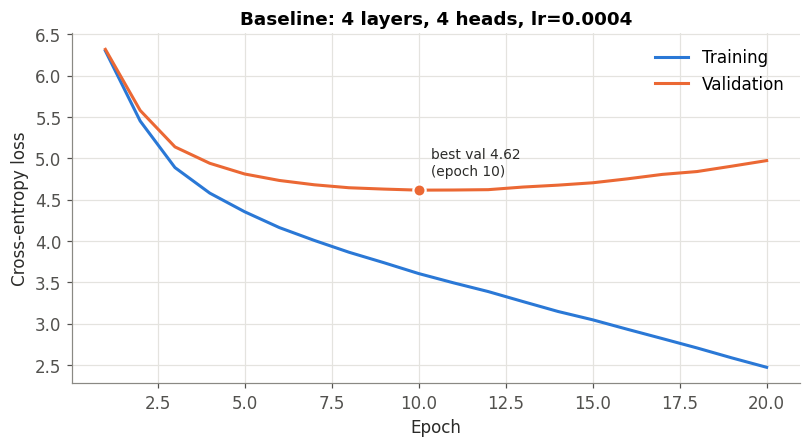

,run,params_M,lr,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Baseline,28.954,0.0,20,4.616,10,101.045,2.473,4.973,2.5,1.392,False


Best val perplexity: 101.0

How the samples change during training:
--- epoch 1 ---
I am sure that as as the,, very



 that.

 have.


 very
;

 I you



�,,
,I you was she. you, were,.
 that

�

--- epoch 5 ---
I am sure that as as the
CHAPTERingley was a

” said she had


“I may be gone to
“that he is not always, and you.”
“I do not like her
�

--- epoch 10 ---
I am sure that
and the other, for you have a great deal of you
himself. I have had not you
she_ did not so certain of my father to be, and I was all.”
Elizabeth, and that he was the

--- epoch 20 ---
I am sure that is not in the
being so much disposed of not so much engaged. This
I did not likely to be
for the next morning at least well married. The prospect of it was not in the
therefore, for that he was going



In [11]:
BASELINE_LR = 4e-4
BASELINE_EPOCHS = 3 if QUICK_MODE else 20

baseline = run_experiment(BASE_CFG, BASELINE_LR, BASELINE_EPOCHS, label="Baseline",
                          sample_epochs=(1, 5, 10, 20))
plot_single(baseline, f"Baseline: {BASE_CFG['n_layers']} layers, {BASE_CFG['n_heads']} heads, "
                      f"lr={BASELINE_LR:g}", "baseline_loss")
save_table(summary_table([baseline]), "baseline_summary")

print(f"Best val perplexity: {math.exp(baseline['best_val_loss']):.1f}")
print("\nHow the samples change during training:")
for ep, txt in sorted(baseline["samples"].items(), key=lambda kv: int(kv[0])):
    print(f"--- epoch {ep} ---\n{txt}\n")

## Phase 6 — Experiment 1: epochs × learning rate

**Design trick (explain it in your report):** with a *constant* learning rate and a fixed seed, a 500-epoch run passes through epoch 5, 10, 20, … exactly as a shorter run would. So **one long run per learning rate** contains all the epoch settings, and we read the losses off at each epoch. The verification cell below trains a separate 20-epoch run to show that its curve matches the first 20 epochs of the long run.

If time is short, set `EXP1_MAX_EPOCHS = 200`.

**Questions to answer in the report**
* Which learning rate converges fastest? Does 1e-2 become unstable, plateau, or diverge? Is 1e-4 too slow?
* At which epoch is validation loss lowest for each LR? What happens afterwards (overfitting: train ↓ while val ↑)?
* How does the train–val gap grow with epochs? What does that say about memorising a single book?
* How does the generated text change between epoch 5, 50 and 500? (Look for copied passages.)

In [12]:
EXP1_LRS = [1e-4, 1e-3, 1e-2]
EXP1_MAX_EPOCHS = 6 if QUICK_MODE else 500
EXP1_CHECKPOINTS = [e for e in (1, 2, 4, 5, 6, 10, 20, 50, 100, 200, 500)
                    if e <= EXP1_MAX_EPOCHS and (QUICK_MODE or e >= 5)]

exp1 = [run_experiment(BASE_CFG, lr, EXP1_MAX_EPOCHS, label=f"lr = {lr:g}", sample_epochs=EXP1_CHECKPOINTS)
        for lr in EXP1_LRS]

[cached] lr = 0.0001                  best val 4.676 @ epoch 25
[cached] lr = 0.001                   best val 4.809 @ epoch 14
[cached] lr = 0.01                    best val 4.951 @ epoch 53


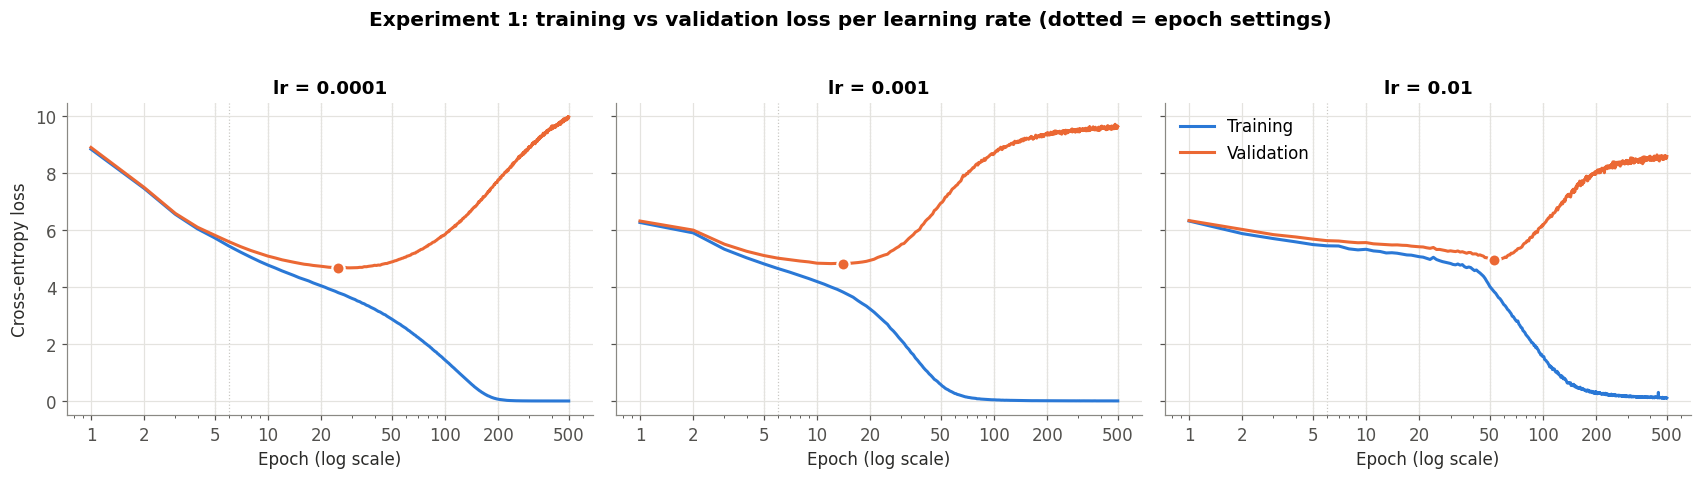

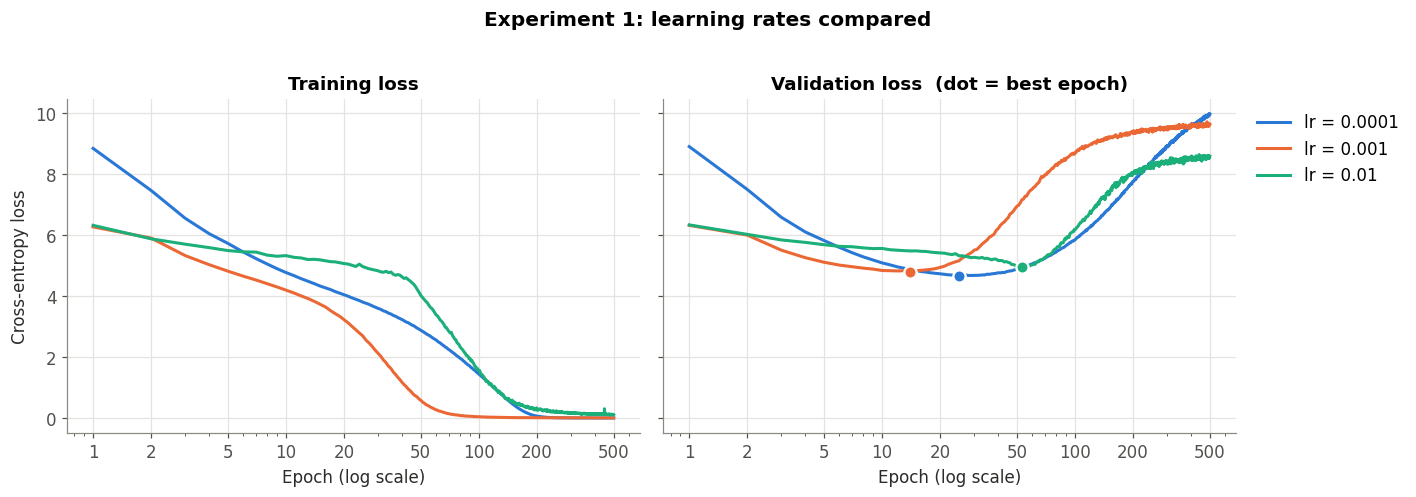

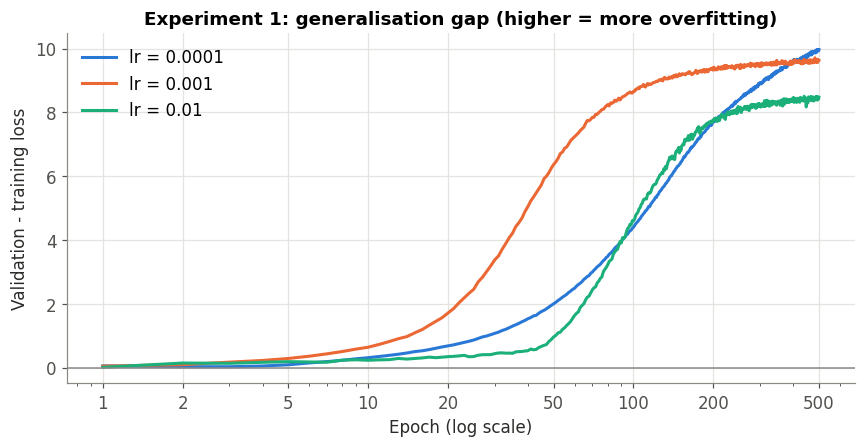

In [13]:
# (a) one panel per learning rate: train vs validation
fig, axes = plt.subplots(1, len(exp1), figsize=(5.2 * len(exp1), 4.2), sharey=True)
for ax, r in zip(np.atleast_1d(axes), exp1):
    ax.plot(*series(r, "train_loss"), color=TRAIN_C, label="Training")
    ax.plot(*series(r, "val_loss"), color=VAL_C, label="Validation")
    ax.plot(r["best_epoch"], r["best_val_loss"], "o", color=VAL_C, ms=8, mec="white", mew=1.5, zorder=5)
    for e in EXP1_CHECKPOINTS:
        ax.axvline(e, color="#c9c8c3", lw=0.8, ls=":", zorder=0)
    log_x(ax)
    ax.set(title=r["label"] + (" (diverged)" if r["diverged"] else ""), xlabel="Epoch (log scale)")
np.atleast_1d(axes)[0].set_ylabel("Cross-entropy loss")
np.atleast_1d(axes)[-1].legend()
fig.suptitle("Experiment 1: training vs validation loss per learning rate (dotted = epoch settings)",
             fontweight="bold", y=1.03)
save_fig(fig, "exp1_per_lr")

# (b) all learning rates overlaid
plot_loss_panels(exp1, "Experiment 1: learning rates compared", "exp1_overlay", logx=True)

# (c) overfitting gap over time
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, r in enumerate(exp1):
    ep, tr = series(r, "train_loss")
    _, va = series(r, "val_loss")
    ax.plot(ep, va - tr, color=SERIES[i], label=r["label"])
ax.axhline(0, color="#8a8984", lw=1)
log_x(ax)
ax.set(xlabel="Epoch (log scale)", ylabel="Validation - training loss",
       title="Experiment 1: generalisation gap (higher = more overfitting)")
ax.legend()
save_fig(fig, "exp1_gap")

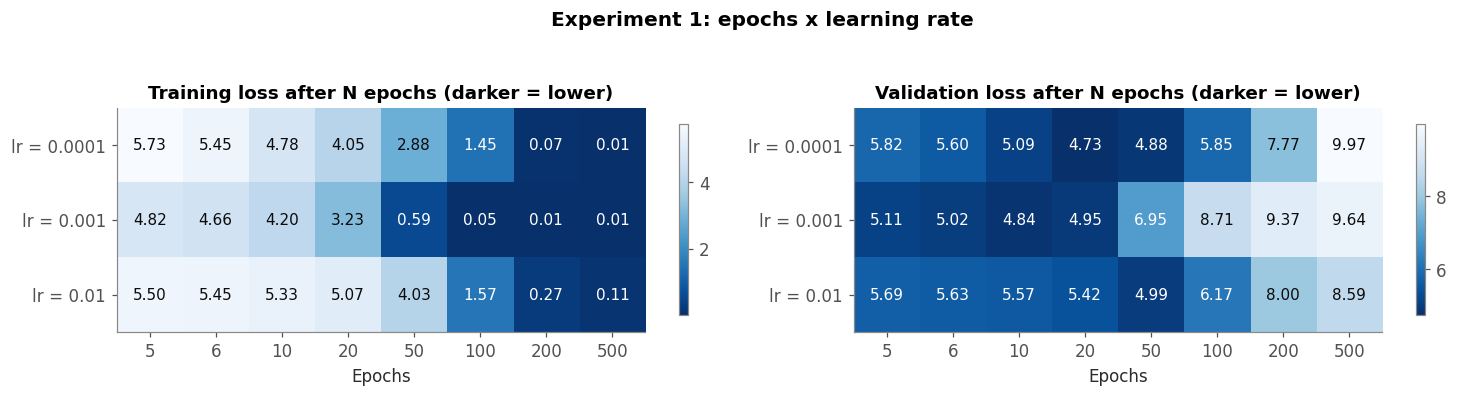

,lr,val@5,val@6,val@10,val@20,val@50,val@100,val@200,val@500
0,lr = 0.0001,5.825,5.601,5.091,4.734,4.885,5.848,7.771,9.973
1,lr = 0.001,5.113,5.020,4.843,4.945,6.952,8.707,9.375,9.645
2,lr = 0.01,5.688,5.634,5.566,5.418,4.992,6.174,8.000,8.588


,lr,train@5,train@6,train@10,train@20,train@50,train@100,train@200,train@500
0,lr = 0.0001,5.732,5.449,4.776,4.048,2.883,1.447,0.067,0.006
1,lr = 0.001,4.822,4.658,4.200,3.230,0.586,0.048,0.014,0.009
2,lr = 0.01,5.497,5.454,5.331,5.070,4.026,1.572,0.272,0.113


,run,params_M,lr,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,lr = 0.0001,28.954,0.000,500,4.676,25,107.344,0.006,9.973,9.967,36.228,False
1,lr = 0.001,28.954,0.001,500,4.809,14,122.662,0.009,9.645,9.635,35.833,False
2,lr = 0.01,28.954,0.010,500,4.951,53,141.364,0.113,8.588,8.475,35.719,False


In [14]:
# (d) loss at each epoch setting: the "epochs x learning rate" grid
def loss_at(run, epoch, key):
    h = run["history"]
    return h[key][h["epoch"].index(epoch)] if epoch in h["epoch"] else float("nan")

grid_val = pd.DataFrame({e: [loss_at(r, e, "val_loss") for r in exp1] for e in EXP1_CHECKPOINTS},
                        index=[r["label"] for r in exp1])
grid_train = pd.DataFrame({e: [loss_at(r, e, "train_loss") for r in exp1] for e in EXP1_CHECKPOINTS},
                          index=[r["label"] for r in exp1])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
for ax, grid, t in ((axes[0], grid_train, "Training loss"), (axes[1], grid_val, "Validation loss")):
    vals = grid.values.astype(float)
    im = ax.imshow(vals, cmap="Blues_r", aspect="auto")
    lo, hi = np.nanmin(vals), np.nanmax(vals)
    for (i, j), v in np.ndenumerate(vals):
        dark = (v - lo) / (hi - lo + 1e-9) < 0.45 if np.isfinite(v) else False
        ax.text(j, i, "-" if not np.isfinite(v) else f"{v:.2f}", ha="center", va="center",
                fontsize=10, color="white" if dark else "#0b0b0b")
    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set(xlabel="Epochs", title=t + " after N epochs (darker = lower)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle("Experiment 1: epochs x learning rate", fontweight="bold", y=1.05)
save_fig(fig, "exp1_grid")

grid_val.columns = [f"val@{c}" for c in grid_val.columns]
save_table(grid_val.reset_index(names="lr").round(3), "exp1_val_grid")
grid_train.columns = [f"train@{c}" for c in grid_train.columns]
save_table(grid_train.reset_index(names="lr").round(3), "exp1_train_grid")
save_table(summary_table(exp1), "exp1_summary")

In [15]:
# Generated text across training, for each learning rate
for r in exp1:
    print("#" * 70, "\n#", r["label"], "\n" + "#" * 70)
    for ep, txt in sorted(r["samples"].items(), key=lambda kv: int(kv[0])):
        print(f"--- epoch {ep} ---\n{txt}\n")

###################################################################### 
# lr = 0.0001 
######################################################################
--- epoch 5 ---
I am sure that as as the to the very


”. Benn of have.


”;

 I you to be by have she on to her, and you was she was you was not,. Benn that is
�

--- epoch 6 ---
I am sure that as as the, and the
with the

”

”

”;

 I you not be a to the


” you was she was you was not,. Bennet is not the

--- epoch 10 ---
I am sure that as as the
CHAPTERingley was a

” said, with
“I have no

“”
”
“Yes; and was she is not was not to me for that is not the

--- epoch 20 ---
I am sure that as you were to be very
with a great enough to make it.”

“I may be nothing to
She is,”
Mr.
“I am not be able to me for me.
�

--- epoch 50 ---
I am sure that you has been
in me so much.”

“I am sure,” said Elizabeth; “and so little I thought I hope you are so
of my mind you, that you may be in your uncle?

--- epoch 100 ---
I am sure that is now

In [16]:
# Verification of the "one long run" trick: separate short run vs first epochs of the long run
RUN_EPOCH_VERIFICATION = True
if RUN_EPOCH_VERIFICATION:
    VERIFY_LR, VERIFY_EPOCHS = 1e-3, (3 if QUICK_MODE else 20)
    short = run_experiment(BASE_CFG, VERIFY_LR, VERIFY_EPOCHS, label=f"separate {VERIFY_EPOCHS}-epoch run")
    long_run = next(r for r in exp1 if r["lr"] == VERIFY_LR)
    a = np.array(short["history"]["val_loss"])
    b = np.array(long_run["history"]["val_loss"][: len(a)])
    print(f"max |difference| in val loss over the first {VERIFY_EPOCHS} epochs: {np.nanmax(np.abs(a - b)):.4f}")
    print("(tiny differences come from non-deterministic GPU kernels; the curves are the same)")

[cached] separate 20-epoch run        best val 4.825 @ epoch 12
max |difference| in val loss over the first 20 epochs: 0.0201
(tiny differences come from non-deterministic GPU kernels; the curves are the same)


### Fixed training settings for Experiments 2–4
Experiments 2–4 change the **architecture**, so learning rate and epochs must stay fixed. They are taken from Experiment 1: the learning rate with the lowest validation loss, trained for about 1.5× its best epoch (clamped to 10–60 epochs), so the curves show where each architecture starts to overfit.

You can override them by hand. Write the chosen values in your report.

In [17]:
best_exp1 = min(exp1, key=lambda r: r["best_val_loss"])
FIXED_LR = best_exp1["lr"]
FIXED_EPOCHS = int(np.clip(math.ceil(1.5 * best_exp1["best_epoch"]), 10, 60))
if QUICK_MODE:
    FIXED_EPOCHS = 2
# FIXED_LR, FIXED_EPOCHS = 1e-3, 30     # <- uncomment to override
print(f"Experiments 2-4 use lr = {FIXED_LR:g}, epochs = {FIXED_EPOCHS}")

Experiments 2-4 use lr = 0.0001, epochs = 38


## Phase 7 — Experiment 2: number of transformer layers (1, 3, 5, 7, 12)
Everything else is fixed: width 256, 4 heads, same LR, epochs, data and seed.

**Questions to answer in the report**
* Does validation loss keep improving with depth, or are there diminishing returns on a dataset this small?
* Do deeper models reach low *training* loss faster, and do they overfit sooner (larger gap)?
* How do parameter count and time per epoch grow with depth? Is the extra cost worth it?
* Compare the generated text of the 1-layer and the 12-layer model.

[cached] 1 layer                      best val 4.664 @ epoch 30
[cached] 3 layers                     best val 4.679 @ epoch 25
[cached] 5 layers                     best val 4.691 @ epoch 30
[cached] 7 layers                     best val 4.668 @ epoch 29
[cached] 12 layers                    best val 4.653 @ epoch 29


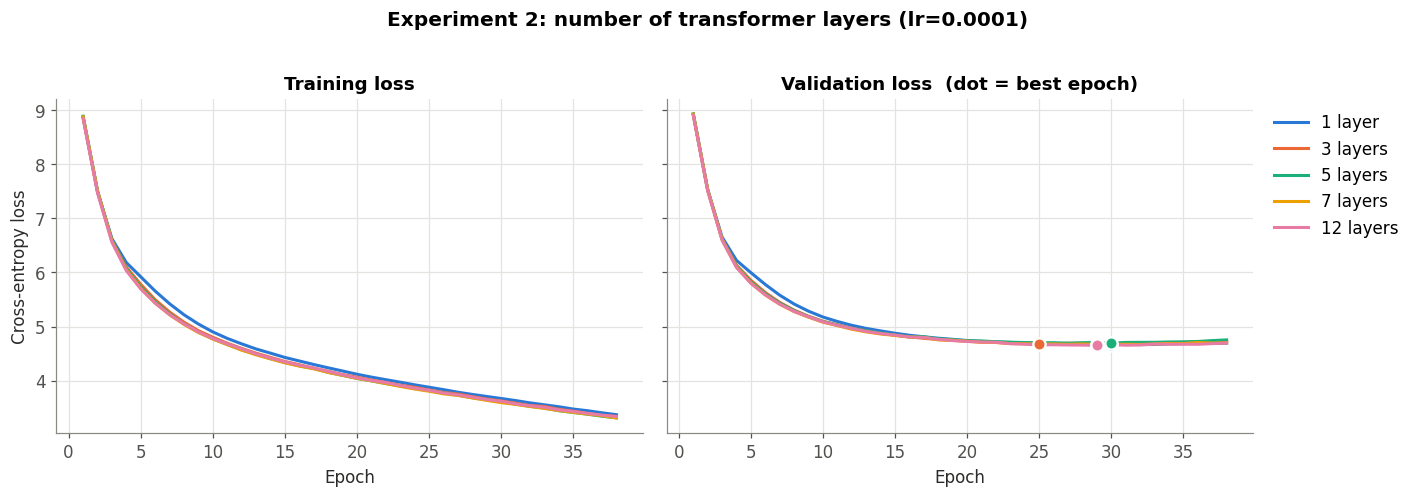

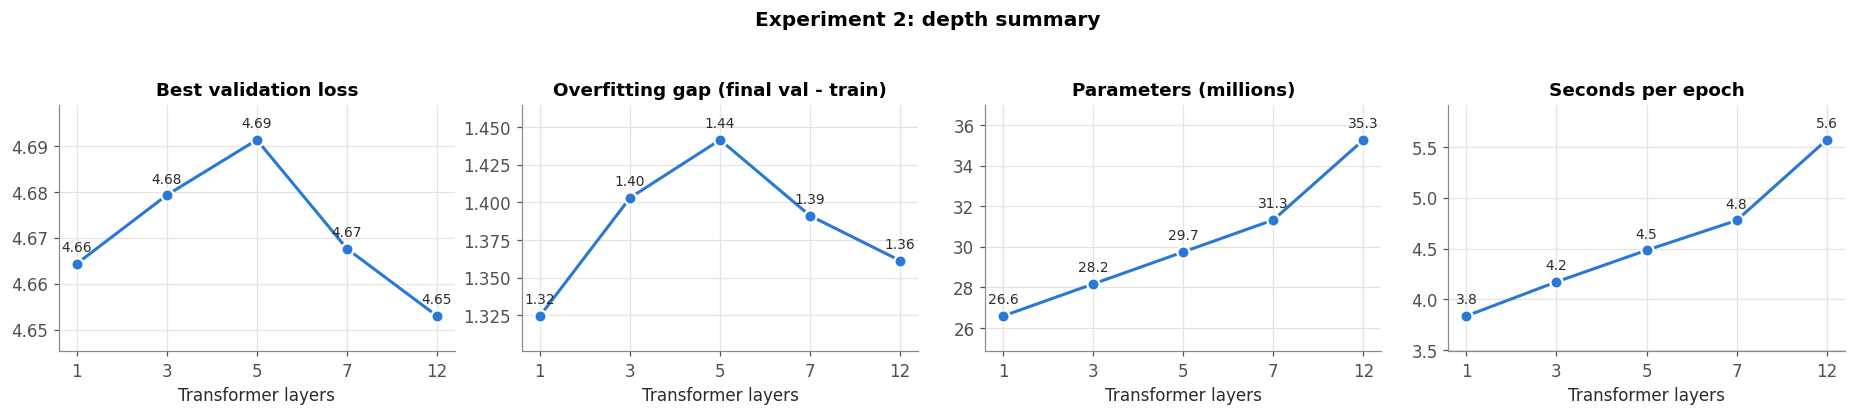

,run,params_M,lr,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged,layers
0,1 layer,26.587,0.0,38,4.664,30,106.096,3.369,4.694,1.325,2.430,False,1
1,3 layers,28.165,0.0,38,4.679,25,107.693,3.337,4.740,1.403,2.642,False,3
2,5 layers,29.743,0.0,38,4.691,30,108.998,3.311,4.753,1.441,2.839,False,5
3,7 layers,31.321,0.0,38,4.668,29,106.444,3.308,4.699,1.391,3.025,False,7
4,12 layers,35.266,0.0,38,4.653,29,104.896,3.335,4.696,1.361,3.528,False,12


=== 1 layer ===
I am sure that the
and, I can bear to make such an hour.” said


“No, you give you know what do do not know. I shall not know.”

“Is it has not
�

=== 3 layers ===
I am sure that the place were to us.”

“It has not have been more than your own;
He is a young man of the carriage is not know, and I was
the world, I am sure I am sure.�

=== 5 layers ===
I am sure that the place were to be very
with a great that he was very far from
of it. As; for a moment, to be done, he is, and,
of the evening of the evening of his own
not he was the

=== 7 layers ===
I am sure that is not in the
for this morning, and I cannot wish it. This is not
was not; but I am determined to be done for the family, and I
of the young man of the subject, as I am sure I told

=== 12 layers ===
I am sure that the place were to be very very much
dressing. Bennet, by a moment. He was to be
for herself to be done; and, to her, and two or
the world was convinced, as she has been at the



In [18]:
EXP2_LAYERS = [1, 3, 5, 7, 12]
exp2 = [run_experiment({**BASE_CFG, "n_layers": L}, FIXED_LR, FIXED_EPOCHS,
                       label=f"{L} layer{'s' if L > 1 else ''}") for L in EXP2_LAYERS]

plot_loss_panels(exp2, f"Experiment 2: number of transformer layers (lr={FIXED_LR:g})", "exp2_layers")
plot_summary(exp2, EXP2_LAYERS, "Transformer layers", "Experiment 2: depth summary", "exp2_summary")
save_table(summary_table(exp2, lambda r: {"layers": r["cfg"]["n_layers"]}), "exp2_summary")
print_samples(exp2)

## Phase 8 — Experiment 3: number of attention heads (1, 2, 4, 8)
`emb_dim` stays 256, so the head size is 256 / 128 / 64 / 32. **The parameter count is identical for every run**: the experiment changes *how* attention capacity is split, not how much capacity there is. Make this point explicitly in the analysis.

**Questions to answer in the report**
* Do several smaller heads beat one large head? Why might they? (Each head can attend to a different pattern: the previous word, the subject of the sentence, punctuation.)
* Is there a point where heads become too small (head_dim = 32) to be useful?
* Are the differences larger or smaller than in the depth experiment? What does that tell you?

[cached] 1 head (head dim 256)        best val 4.666 @ epoch 29
[cached] 2 heads (head dim 128)       best val 4.666 @ epoch 29
[cached] 4 heads (head dim 64)        best val 4.676 @ epoch 25
[cached] 8 heads (head dim 32)        best val 4.689 @ epoch 25


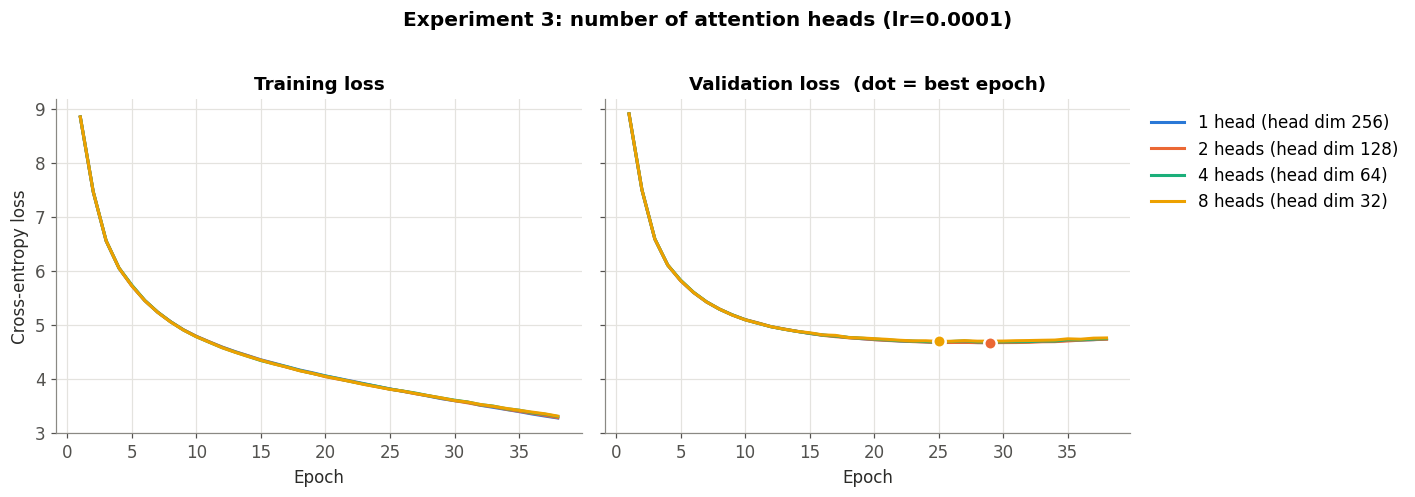

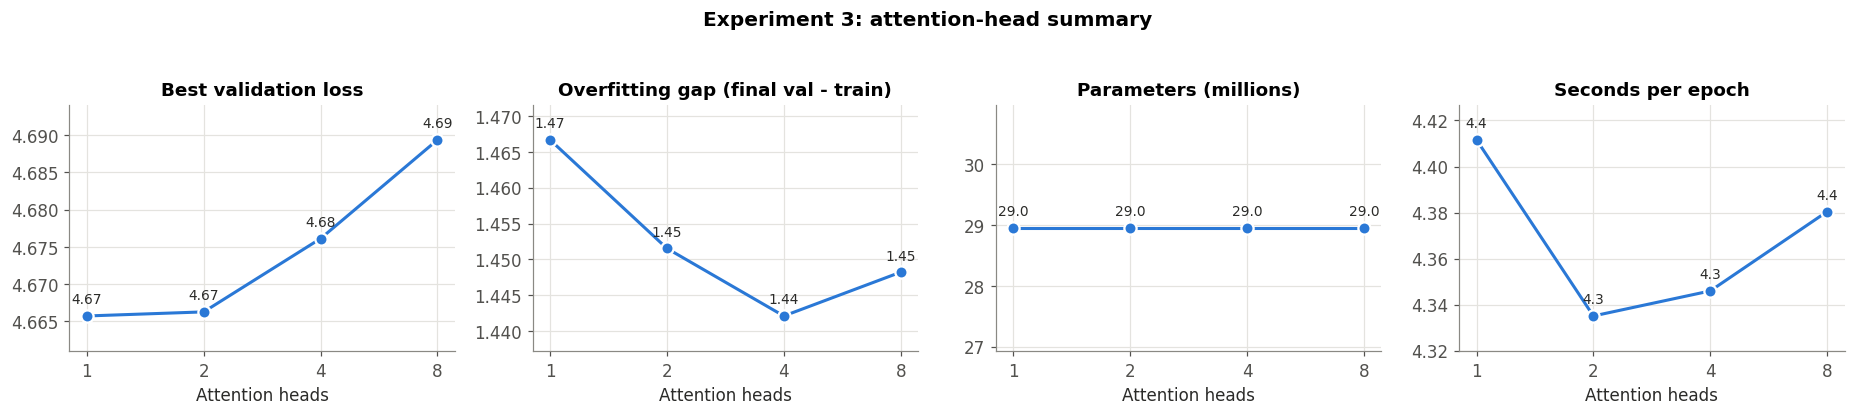

,run,params_M,lr,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged,heads,head_dim
0,1 head (head dim 256),28.954,0.0,38,4.666,29,106.241,3.271,4.738,1.467,2.794,False,1,256
1,2 heads (head dim 128),28.954,0.0,38,4.666,29,106.299,3.278,4.730,1.452,2.746,False,2,128
2,4 heads (head dim 64),28.954,0.0,38,4.676,25,107.352,3.299,4.741,1.442,2.752,False,4,64
3,8 heads (head dim 32),28.954,0.0,38,4.689,25,108.785,3.306,4.754,1.448,2.774,False,8,32


=== 1 head (head dim 256) ===
I am sure that I am sure, can me is much more than I
you has not. You are not very few minutes”

“I do not afraid of your father is not.”

“Is it has not at the

=== 2 heads (head dim 128) ===
I am sure that
and I amiable. What be a great deal of all the
of his character. I told you may be done; for you do do not hope to
of your sister.”

“Is it has not
�

=== 4 heads (head dim 64) ===
I am sure that I am sure, can me so much more
will be gone to give my aunt, I am sure;
dressing, to be certain, I cannot be married. I will not like _myself.”

“I

=== 8 heads (head dim 32) ===
I am sure that as you were to be very
with a word, but, that I am sure I amiable. I
she_ did not be certain, I cannot be always always able to be all.”

CHAPTER XXXV.





In [19]:
EXP3_HEADS = [1, 2, 4, 8]
exp3 = [run_experiment({**BASE_CFG, "n_heads": h}, FIXED_LR, FIXED_EPOCHS,
                       label=f"{h} head{'s' if h > 1 else ''} (head dim {BASE_CFG['emb_dim'] // h})")
        for h in EXP3_HEADS]

plot_loss_panels(exp3, f"Experiment 3: number of attention heads (lr={FIXED_LR:g})", "exp3_heads")
plot_summary(exp3, EXP3_HEADS, "Attention heads", "Experiment 3: attention-head summary", "exp3_summary")
save_table(summary_table(exp3, lambda r: {"heads": r["cfg"]["n_heads"],
                                          "head_dim": r["cfg"]["emb_dim"] // r["cfg"]["n_heads"]}), "exp3_summary")
print_samples(exp3)

## Phase 9 — Experiment 4: ablation studies
Each run removes **one** component from **every** transformer block. The full model at identical settings is the reference.

The **gradient-norm** plot is extra evidence: residual connections and LayerNorm both exist to keep gradients and activations at a healthy scale.

**Questions to answer for each ablation**
* **No LayerNorm:** is training slower or noisier? Are there loss spikes? What does normalisation do to the scale of activations?
* **No shortcut:** how much worse is it? Why do residual connections matter for gradient flow? Look at the deep (12-layer) version below, where the effect should be most visible.
* **No FFN:** the model loses about 2/3 of its block parameters. Is the loss worse because of missing capacity, or because the FFN does a specific job (a per-token "memory")? Use the parameter count in the table.
* **Inference quality:** compare the generated text side by side. Is it grammatical? Does it repeat? Is it gibberish?

[cached] Full model (reference)       best val 4.676 @ epoch 25
[cached] No LayerNorm                 best val 4.627 @ epoch 37
[cached] No shortcut                  best val 5.564 @ epoch 38
[cached] No FFN                       best val 4.747 @ epoch 37


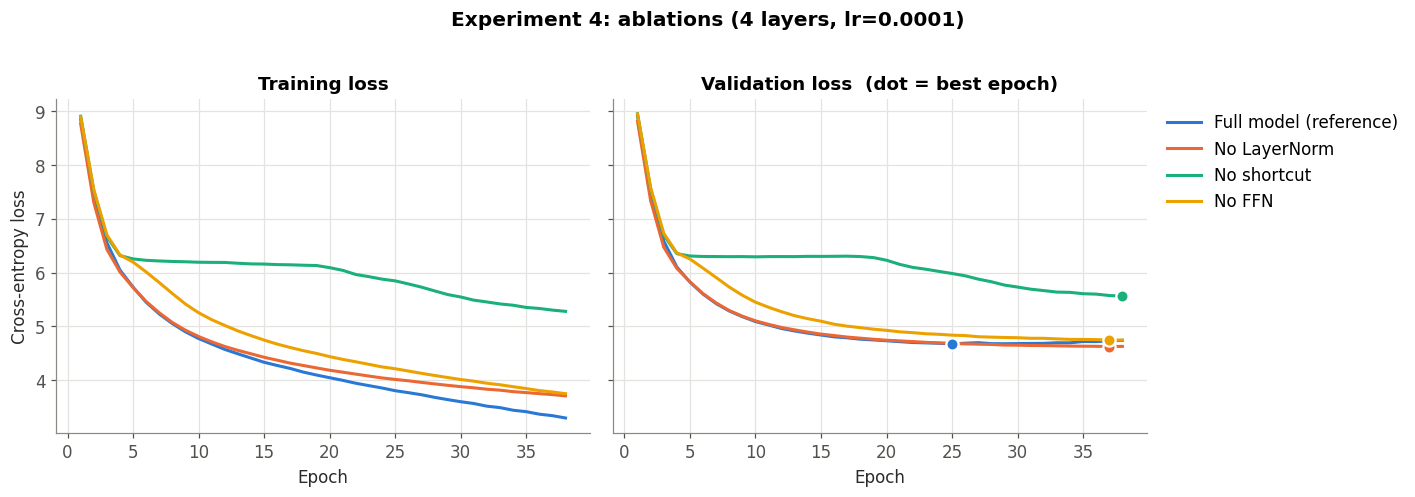

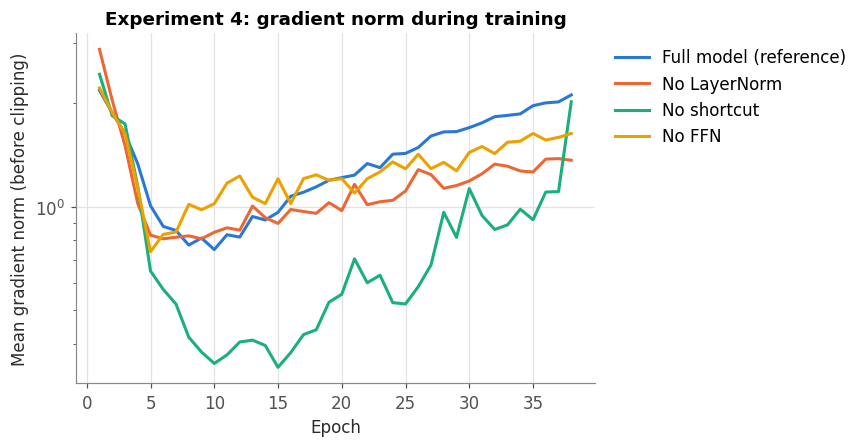

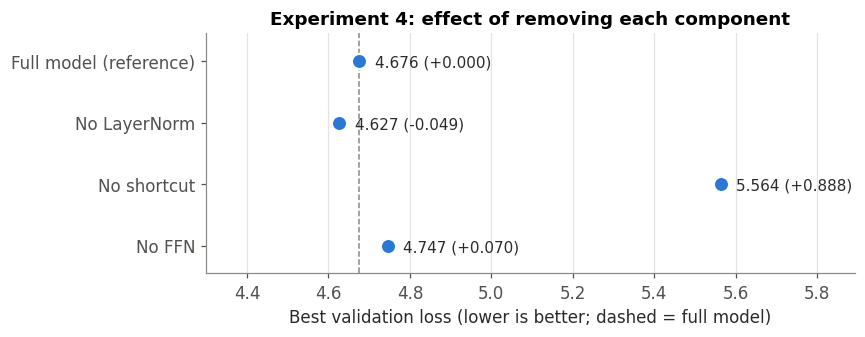

,run,params_M,lr,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Full model (reference),28.954,0.0,38,4.676,25,107.352,3.299,4.741,1.442,2.752,False
1,No LayerNorm,28.950,0.0,38,4.627,37,102.206,3.710,4.630,0.919,2.705,False
2,No shortcut,28.954,0.0,38,5.564,38,260.903,5.281,5.564,0.283,2.726,False
3,No FFN,26.849,0.0,38,4.747,37,115.182,3.751,4.748,0.997,2.548,False


=== Full model (reference) ===
I am sure that I am sure, can me so much more
will be gone to give my aunt, I am sure;
dressing, to be certain, I cannot be married. I will not like _myself.”

“I

=== No LayerNorm ===
I am sure that as you were to be very
with a word.”

“I do not know;

“I_ do do not so often! I have happened.”
“I do not like is not the

=== No shortcut ===
I am sure that as as the,,.
� theley.”
��
I I have



 I you not be
��
�Mr, is you.���“” it has

�

=== No FFN ===
I am sure that as you were to be very
with the day. Bingley“I
I do. You have been a moment you
She do do not a great deal of your sister.”

“Is it that is only the



In [20]:
ABLATIONS = {
    "Full model (reference)": {},
    "No LayerNorm": {"use_norm": False},
    "No shortcut": {"use_shortcut": False},
    "No FFN": {"use_ffn": False},
}
exp4 = [run_experiment({**BASE_CFG, **change}, FIXED_LR, FIXED_EPOCHS, label=name)
        for name, change in ABLATIONS.items()]

plot_loss_panels(exp4, f"Experiment 4: ablations ({BASE_CFG['n_layers']} layers, lr={FIXED_LR:g})", "exp4_ablations")
plot_metric(exp4, "grad_norm", "Mean gradient norm (before clipping)",
            "Experiment 4: gradient norm during training", "exp4_grad_norm", logy=True)

# best validation loss per variant: dot plot (differences can be small, so the axis is not forced to 0)
fig, ax = plt.subplots(figsize=(8, 3.2))
names = [r["label"] for r in exp4][::-1]
vals = [r["best_val_loss"] for r in exp4][::-1]
ax.axvline(exp4[0]["best_val_loss"], color="#8a8984", lw=1, ls="--", zorder=0)
ax.plot(vals, names, "o", color=SERIES[0], ms=10, mec="white", mew=1.5)
ref = exp4[0]["best_val_loss"]
for y, v in enumerate(vals):
    ax.annotate(f"{v:.3f} ({v - ref:+.3f})", (v, y), textcoords="offset points", xytext=(10, -4),
                fontsize=10, color="#2b2b29")
ax.set(xlabel="Best validation loss (lower is better; dashed = full model)",
       title="Experiment 4: effect of removing each component")
ax.grid(axis="y", visible=False)
ax.margins(x=0.35, y=0.15)
save_fig(fig, "exp4_bar")

save_table(summary_table(exp4), "exp4_summary")
print_samples(exp4)

### Experiment 4b — the same ablations in a deep (12-layer) model
Removing residuals or normalisation hurts more as the network gets deeper, because gradients must pass through every layer. The 12-layer full model is reused from Experiment 2, so it is not retrained.

[cached] Full model (reference) [12 layers] best val 4.653 @ epoch 29
[cached] No LayerNorm [12 layers]     best val 4.613 @ epoch 37
[cached] No shortcut [12 layers]      best val 6.316 @ epoch 11
[cached] No FFN [12 layers]           best val 4.824 @ epoch 37


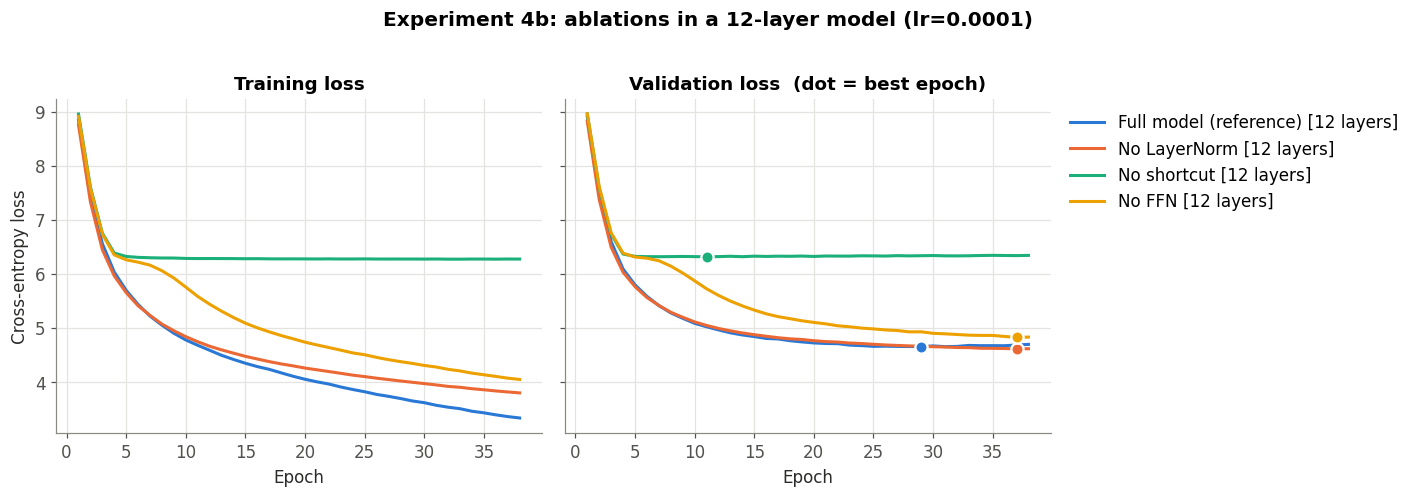

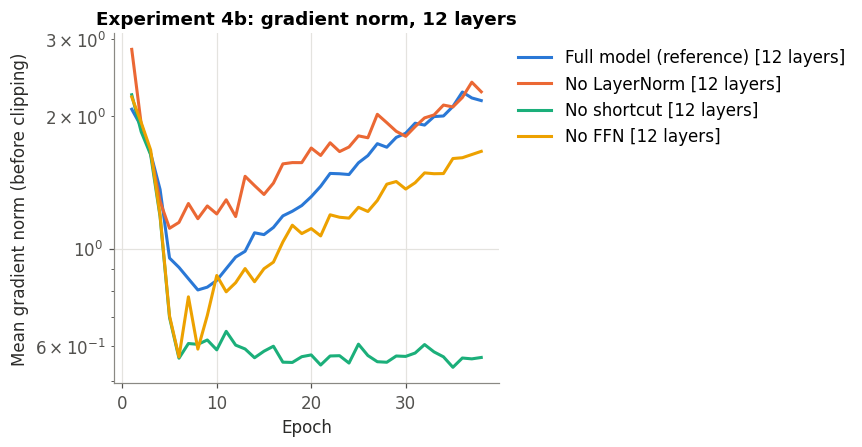

,run,params_M,lr,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Full model (reference) [12 layers],35.266,0.0,38,4.653,29,104.896,3.335,4.696,1.361,3.528,False
1,No LayerNorm [12 layers],35.253,0.0,38,4.613,37,100.758,3.799,4.616,0.817,3.411,False
2,No shortcut [12 layers],35.266,0.0,38,6.316,11,553.309,6.274,6.342,0.068,3.398,False
3,No FFN [12 layers],28.953,0.0,38,4.824,37,124.509,4.047,4.831,0.783,2.933,False


=== Full model (reference) [12 layers] ===
I am sure that the place were to be very very much
dressing. Bennet, by a moment. He was to be
for herself to be done; and, to her, and two or
the world was convinced, as she has been at the

=== No LayerNorm [12 layers] ===
I am sure that
and the matter, for
with a great deal to make it. This
CHAPTER XX.

“You you to be a great deal in the
” replied Mr. Darcy was not to me for the gentlemen
�

=== No shortcut [12 layers] ===
I am sure that as as the,,.
 be the
 that but, of have.


.
;

 I you


,�,,
,
 you was she. you,,,. it that is
 the

=== No FFN [12 layers] ===
I am sure that as I were to be very
with the day.” said Elizabeth,

“That you may be done you not be a wife, “to be able to be little of you, my sister. I am
to the



In [21]:
RUN_DEEP_ABLATIONS = True
if RUN_DEEP_ABLATIONS:
    DEEP = {**BASE_CFG, "n_layers": 12}
    exp4_deep = [run_experiment({**DEEP, **change}, FIXED_LR, FIXED_EPOCHS, label=name + " [12 layers]")
                 for name, change in ABLATIONS.items()]
    plot_loss_panels(exp4_deep, f"Experiment 4b: ablations in a 12-layer model (lr={FIXED_LR:g})", "exp4b_deep_ablations")
    plot_metric(exp4_deep, "grad_norm", "Mean gradient norm (before clipping)",
                "Experiment 4b: gradient norm, 12 layers", "exp4b_grad_norm", logy=True)
    save_table(summary_table(exp4_deep), "exp4b_summary")
    print_samples(exp4_deep)
else:
    exp4_deep = []

## Phase 10 — Master results table, samples, and export for Overleaf

In [22]:
groups = [("Baseline", [baseline]), ("Exp1 LR x epochs", exp1), ("Exp2 layers", exp2),
          ("Exp3 heads", exp3), ("Exp4 ablations", exp4), ("Exp4b deep ablations", exp4_deep)]
master = pd.concat([summary_table(runs, lambda r, g=g: {"experiment": g, "layers": r["cfg"]["n_layers"],
                                                        "heads": r["cfg"]["n_heads"]})
                    for g, runs in groups if runs], ignore_index=True)
master = master[["experiment", "run", "layers", "heads", "lr", "epochs", "params_M", "best_val", "best_epoch",
                 "best_val_ppl", "final_train", "final_val", "gap", "min_per_run", "diverged"]]
save_table(master, "master_results")

# every generated sample in one Markdown file (copy the best ones into your report)
with open(os.path.join(TAB_DIR, f"{RUN_PREFIX}generated_samples.md"), "w", encoding="utf-8") as f:
    f.write(f"# Generated samples (prompt: {PROMPT!r}, temperature 0.8, top-k 40, seed {SEED})\n\n")
    for g, runs in groups:
        for r in runs:
            f.write(f"## {g} - {r['label']}\n\n")
            for ep, txt in sorted(r["samples"].items(), key=lambda kv: int(kv[0])):
                f.write(f"**epoch {ep}:** {txt}\n\n")
print("Saved generated_samples.md")

,experiment,run,layers,heads,lr,epochs,params_M,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Baseline,Baseline,4,4,0.000,20,28.954,4.616,10,101.045,2.473,4.973,2.500,1.392,False
1,Exp1 LR x epochs,lr = 0.0001,4,4,0.000,500,28.954,4.676,25,107.344,0.006,9.973,9.967,36.228,False
2,Exp1 LR x epochs,lr = 0.001,4,4,0.001,500,28.954,4.809,14,122.662,0.009,9.645,9.635,35.833,False
3,Exp1 LR x epochs,lr = 0.01,4,4,0.010,500,28.954,4.951,53,141.364,0.113,8.588,8.475,35.719,False
4,Exp2 layers,1 layer,1,4,0.000,38,26.587,4.664,30,106.096,3.369,4.694,1.325,2.430,False
5,Exp2 layers,3 layers,3,4,0.000,38,28.165,4.679,25,107.693,3.337,4.740,1.403,2.642,False
6,Exp2 layers,5 layers,5,4,0.000,38,29.743,4.691,30,108.998,3.311,4.753,1.441,2.839,False
7,Exp2 layers,7 layers,7,4,0.000,38,31.321,4.668,29,106.444,3.308,4.699,1.391,3.025,False
8,Exp2 layers,12 layers,12,4,0.000,38,35.266,4.653,29,104.896,3.335,4.696,1.361,3.528,False
9,Exp3 heads,1 head (head dim 256),4,1,0.000,38,28.954,4.666,29,106.241,3.271,4.738,1.467,2.794,False


Saved generated_samples.md


In [23]:
# Zip figures + tables, and download them (upload the zip to Overleaf)
import zipfile
archive = os.path.join(SAVE_DIR, f"{RUN_PREFIX}report_assets.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ("figures", "tables"):
        for fn in sorted(os.listdir(os.path.join(SAVE_DIR, sub))):
            if fn.startswith(RUN_PREFIX) or fn == "dataset_stats.json":
                z.write(os.path.join(SAVE_DIR, sub, fn), arcname=f"{sub}/{fn}")
        print(sub, "->", len(os.listdir(os.path.join(SAVE_DIR, sub))), "files")
print("Archive:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

figures -> 28 files
tables -> 20 files
Archive: /content/drive/MyDrive/LLM_Scratch_Assignment/report_assets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mapping outputs to the report

| Report section | Figures (`figures/*.pdf`) | Tables (`tables/*`) |
|---|---|---|
| Setup / data | – | `dataset_stats.json` |
| Baseline | `baseline_loss` | `baseline_summary` |
| Exp 1 | `exp1_per_lr`, `exp1_overlay`, `exp1_gap`, `exp1_grid` | `exp1_val_grid`, `exp1_train_grid`, `exp1_summary` |
| Exp 2 | `exp2_layers`, `exp2_summary` | `exp2_summary` |
| Exp 3 | `exp3_heads`, `exp3_summary` | `exp3_summary` |
| Exp 4 | `exp4_ablations`, `exp4_grad_norm`, `exp4_bar`, `exp4b_*` | `exp4_summary`, `exp4b_summary` |
| Summary page | – | `master_results`, `generated_samples.md` |

For every figure, the report should say: **(1) what you see, (2) why it happens (theory), (3) what it implies.**
Also list the limitations: a single book (small data), a scaled-down model, a single seed, and a constant learning rate without warm-up or decay.

# Phase 11 — Follow-up experiments

These cells go **at the end** of the main notebook. They use the variables and functions defined above (`run_experiment`, `BASE_CFG`, `ABLATIONS`, `exp2`, `FIXED_LR`, …), so first run all earlier cells. Finished runs load from Drive in seconds, so nothing is retrained.

| Cell | What it does | GPU time on a T4 |
|---|---|---|
| 11.0 | Helpers: seed support, display fixes | – |
| 11.1 | **Exp 4c:** ablations at a higher learning rate (1e-3), trained long enough for every variant to reach its best epoch | ~40 min |
| 11.2 | **Exp 2 & 3 with 3 seeds:** mean ± std, to tell real differences from random luck | ~50 min |
| 11.3 | Re-save tables with the learning rate shown correctly, fixed plots, updated master table, zip | ~1 min |

Every run is saved to Drive as before. If Colab disconnects, run everything again and it continues where it stopped.

## 11.0 — Helpers
* **Seeds:** `run_with_seed(seed, cfg, lr, epochs)` trains with another seed. Runs with the original seed keep their old names, so they are loaded from Drive; other seeds are saved as separate runs (`..._seed42`).
* **Display fixes:** tables now show the learning rate as `1e-04` instead of the rounded `0.0`, and log-scaled y-axes show plain numbers.

This cell only *adds* or *replaces* helper functions. It doesn't change any earlier cell or any saved run.

In [24]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

# --- seed support -------------------------------------------------------------
# (globals().get(...) keeps the originals if this cell is run twice)
_DEFAULT_SEED = globals().get("_DEFAULT_SEED", SEED)
_base_run_key = globals().get("_base_run_key", run_key)


def run_key(cfg, lr, epochs):
    key = _base_run_key(cfg, lr, epochs)
    return key if SEED == _DEFAULT_SEED else f"{key}_seed{SEED}"


def run_with_seed(seed, cfg, lr, epochs, **kwargs):
    """run_experiment with another seed (changes initial weights, data order and dropout)."""
    global SEED
    old_seed, SEED = SEED, seed
    try:
        run = run_experiment(cfg, lr, epochs, **kwargs)
    finally:
        SEED = old_seed
    run["seed"] = seed
    return run


# --- display fixes ------------------------------------------------------------
def fmt_lr(lr):
    return f"{lr:.0e}"


def summary_table(runs, extra=None):
    rows = []
    for r in runs:
        row = {"run": r["label"], "params_M": r["params"] / 1e6, "lr": fmt_lr(r["lr"]),
               "seed": r.get("seed", _DEFAULT_SEED), "epochs": r["epochs_completed"],
               "best_val": r["best_val_loss"], "best_epoch": r["best_epoch"],
               "best_val_ppl": math.exp(r["best_val_loss"]),
               "final_train": r["final_train_loss"], "final_val": r["final_val_loss"],
               "gap": r["final_val_loss"] - r["final_train_loss"],
               "min_per_run": r["time_sec"] / 60, "diverged": r["diverged"]}
        rows.append({**row, **(extra(r) if extra else {})})
    return pd.DataFrame(rows).round(3)


def log_y(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())


def plot_metric(runs, key, ylabel, title, name, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i, r in enumerate(runs):
        ax.plot(*series(r, key), color=SERIES[i % len(SERIES)], label=r["label"])
    ax.set(xlabel="Epoch", ylabel=ylabel, title=title)
    if logx:
        log_x(ax)
    if logy:
        log_y(ax)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    save_fig(fig, name)


# --- new plots / checks -------------------------------------------------------
def plot_best_dots(runs, title, name):
    """Best validation loss of each run and the epoch where it was reached. Dashed line = first run."""
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(runs) + 1.6))
    labels = [r["label"] for r in runs][::-1]
    vals = [r["best_val_loss"] for r in runs][::-1]
    epochs = [r["best_epoch"] for r in runs][::-1]
    ref = runs[0]["best_val_loss"]
    ax.axvline(ref, color="#8a8984", lw=1, ls="--", zorder=0)
    ax.plot(vals, labels, "o", color=SERIES[0], ms=10, mec="white", mew=1.5)
    for y, (v, e) in enumerate(zip(vals, epochs)):
        ax.annotate(f"{v:.3f} ({v - ref:+.3f}) at epoch {e}", (v, y), textcoords="offset points",
                    xytext=(10, -4), fontsize=10, color="#2b2b29")
    ax.set(xlabel="Best validation loss (lower is better; dashed = full model)", title=title)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.5, y=0.15)
    save_fig(fig, name)


def check_converged(runs):
    """A best epoch in the last 10% of training means the run was still improving when it stopped."""
    for r in runs:
        if r["diverged"]:
            status = "DIVERGED (loss became NaN/inf)"
        elif r["best_epoch"] >= 0.9 * r["epochs_completed"]:
            status = "still improving at the end -> increase the epochs for a fair comparison"
        else:
            status = "reached its minimum ✓"
        print(f"  {r['label']:<26} best epoch {r['best_epoch']:>3} / {r['epochs_completed']:<3}  {status}")


def finish_cell():
    if "snapshot_notebook" in globals():
        snapshot_notebook()


print("Phase 11 helpers ready. Default seed:", _DEFAULT_SEED)


Phase 11 helpers ready. Default seed: 123


## 11.1 — Experiment 4c: ablations at a higher learning rate

**Why repeat the ablations?** In Experiment 4 two things hid the real effect of each component:

1. **The learning rate was very low (1e-4).** LayerNorm and residual connections mainly keep training *stable*. With tiny update steps nothing becomes unstable, so the model doesn't need them. At **1e-3** (also used in Experiment 1) their stabilising role can show up.
2. **Training stopped before every variant had peaked.** The full model peaked at epoch 25 and then overfitted, while No-LayerNorm and No-FFN were still improving at epoch 37 of 38. A fair comparison uses **each model's best validation loss**, so here every variant trains for 60 epochs, and `check_converged` confirms that each one actually reached its minimum.

**Questions to answer in the report**
* Does removing LayerNorm hurt more at 1e-3 than at 1e-4? Look for loss spikes, a higher plateau or divergence, and for larger, noisier gradient norms.
* Is removing the shortcut even worse at a higher learning rate, especially with 12 layers?
* Once every variant has reached its minimum, how far is No-FFN behind the full model? Relate this to the parameters it lost.
* Compare with Experiment 4 (the table at the end of this cell): which conclusions change with the learning rate, and which hold at both?


=== Ablations: 4 layers, lr 1e-03, 60 epochs ===
  Full model (reference) | epoch    6/60 | train 4.656 | val 5.017 |     25s
  Full model (reference) | epoch   12/60 | train 4.009 | val 4.818 |     52s
  Full model (reference) | epoch   18/60 | train 3.462 | val 4.898 |     78s
  Full model (reference) | epoch   24/60 | train 2.800 | val 5.095 |    104s
  Full model (reference) | epoch   30/60 | train 2.129 | val 5.474 |    132s
  Full model (reference) | epoch   36/60 | train 1.512 | val 5.885 |    158s
  Full model (reference) | epoch   42/60 | train 1.031 | val 6.329 |    184s
  Full model (reference) | epoch   48/60 | train 0.681 | val 6.745 |    210s
  Full model (reference) | epoch   54/60 | train 0.444 | val 7.119 |    237s
  Full model (reference) | epoch   60/60 | train 0.273 | val 7.454 |    263s
[done]   Full model (reference)       best val 4.818 @ epoch 12 | 4.4 min
  No LayerNorm | epoch    6/60 | train 3.491 | val 4.646 |     26s
  No LayerNorm | epoch   12/60 | train 

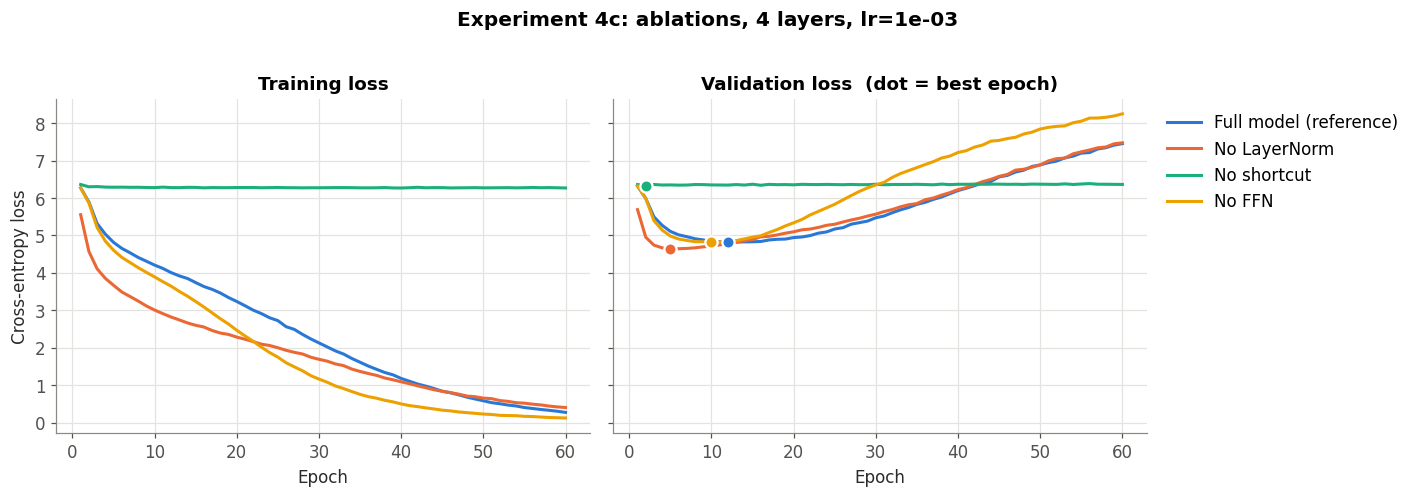

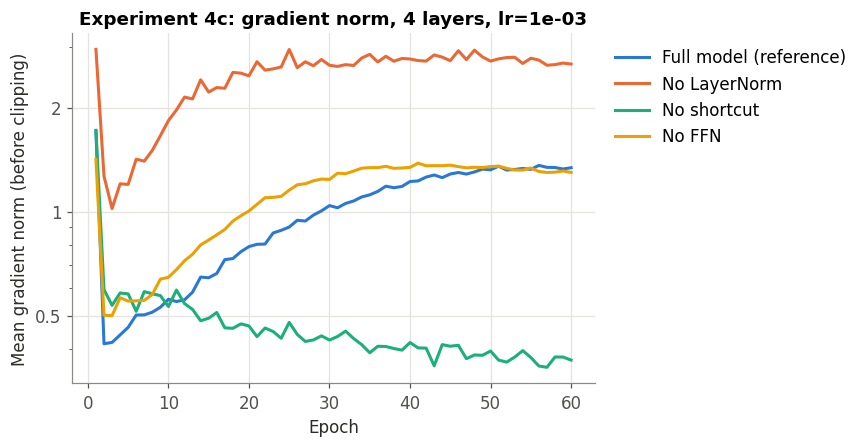

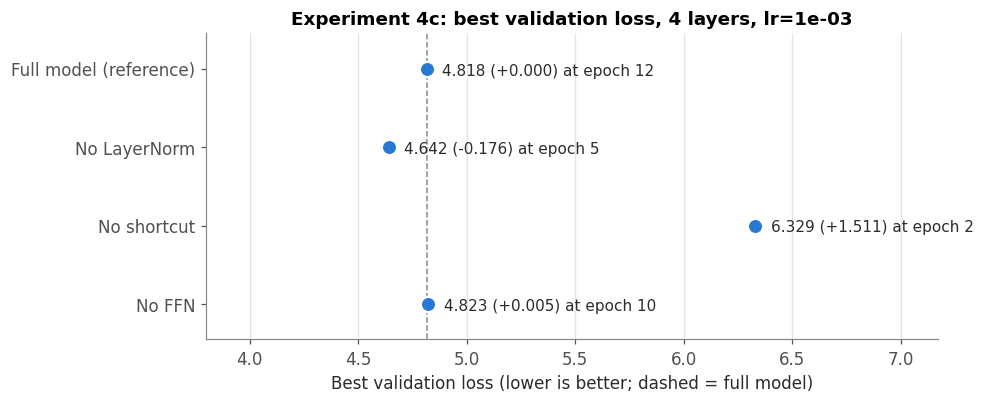


Convergence check, 4 layers:
  Full model (reference)     best epoch  12 / 60   reached its minimum ✓
  No LayerNorm               best epoch   5 / 60   reached its minimum ✓
  No shortcut                best epoch   2 / 60   reached its minimum ✓
  No FFN                     best epoch  10 / 60   reached its minimum ✓


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged,layers
0,Full model (reference),28.954,1e-03,123,60,4.818,12,123.690,0.273,7.454,7.182,4.379,False,4
1,No LayerNorm,28.950,1e-03,123,60,4.642,5,103.749,0.403,7.476,7.072,4.301,False,4
2,No shortcut,28.954,1e-03,123,60,6.329,2,560.433,6.269,6.364,0.095,4.341,False,4
3,No FFN,26.849,1e-03,123,60,4.823,10,124.358,0.123,8.250,8.127,4.066,False,4


=== Full model (reference) ===
I am sure that when we were very attentive to the very
subject.”

“If he.”

“If he cried Mrs. JenkinsI am sorry with two or little
my instrument,” said Mrs. Bennet

=== No LayerNorm ===
I am sure that theOh, my word is disposed to take it.”

Their first thought it of all; but he first witnessing his altered by Derbyshire.


And yet seen such a word for Derbyshire. A discretion in

=== No shortcut ===
I am sure that as as the,,.
 be the
 that., of have.


.
;

 I you
 
,�,,
,
 you was she. you was.,. it that is
 the

=== No FFN ===
I am sure that the become of her, and her, and her poultry. or
affair is perfectly sure, and Jane may be attended to her, if he had never joined them.”

“You were all good or that her weeks.



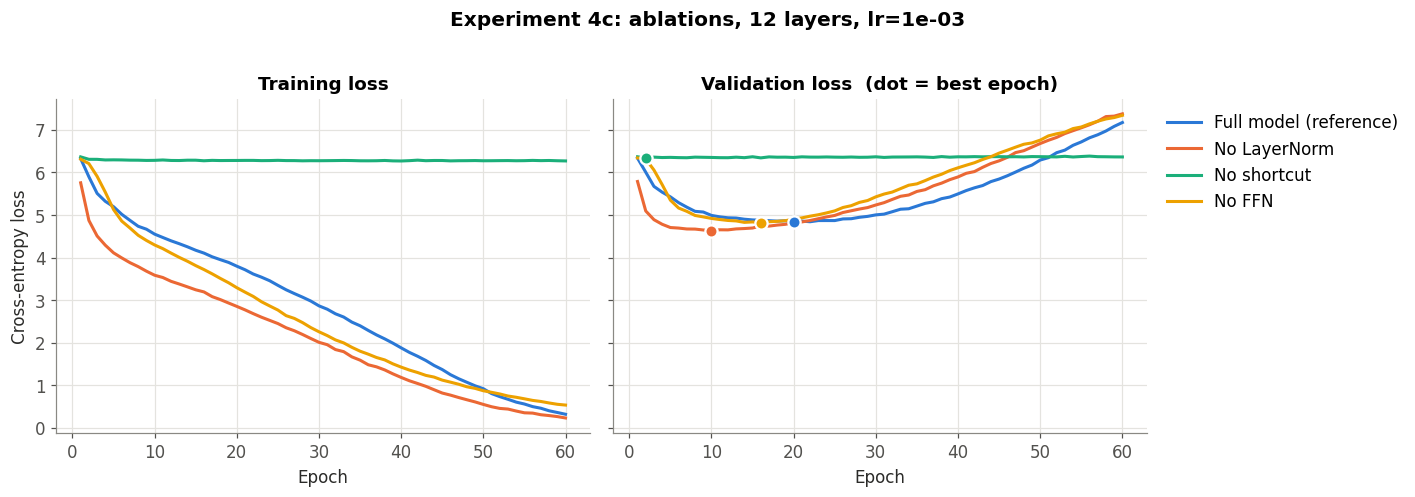

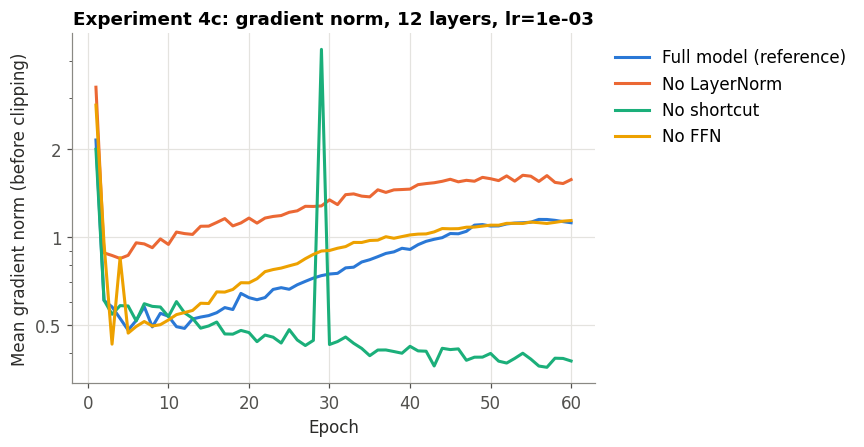

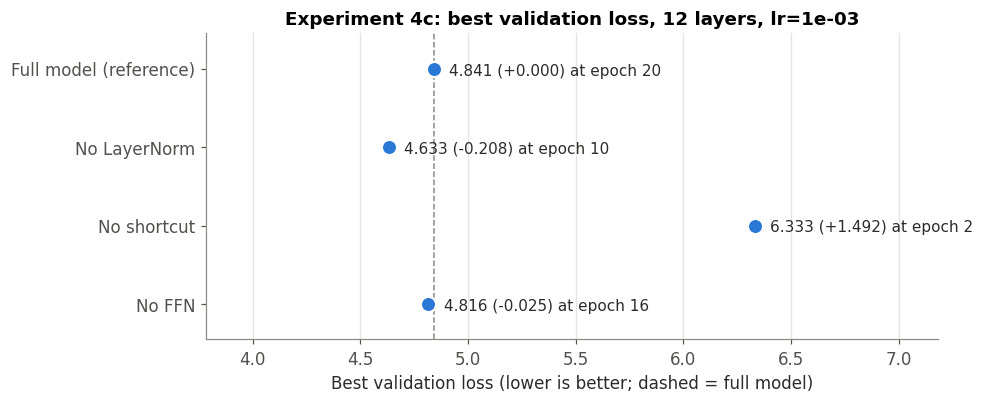


Convergence check, 12 layers:
  Full model (reference)     best epoch  20 / 60   reached its minimum ✓
  No LayerNorm               best epoch  10 / 60   reached its minimum ✓
  No shortcut                best epoch   2 / 60   reached its minimum ✓
  No FFN                     best epoch  16 / 60   reached its minimum ✓


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged,layers
0,Full model (reference),35.266,1e-03,123,60,4.841,20,126.587,0.320,7.171,6.851,5.636,False,12
1,No LayerNorm,35.253,1e-03,123,60,4.633,10,102.791,0.233,7.375,7.143,5.479,False,12
2,No shortcut,35.266,1e-03,123,60,6.333,2,562.960,6.269,6.363,0.094,5.455,False,12
3,No FFN,28.953,1e-03,123,60,4.816,16,123.492,0.536,7.340,6.804,4.689,False,12


=== Full model (reference) ===
I am sure that he arrived to consider him twice, so easily
now_ meet them. What is when I have told you should not know what
now meet them home as to expose what I meet by either. Your father. His father, that is
now

=== No LayerNorm ===
I am sure that is as it may be very dressed.”

“Wickham did. I hardly have not so undeserving young man so we meet
 us?”
“What does it?”

“But

=== No shortcut ===
I am sure that as as the,,.
 be the
 that., of have.


.
;

 I you
 
,�,,
,
 you was she. you was.,. it that is
 the

=== No FFN ===
I am sure that it as the near
advantage to theusage of all of Lydia’s family must have hoped for him,
businessselves.
She would not bring him from an connection with Lydia was too much for her for her
interest acquainted



,layers,variant,"best_val (lr 1e-04, 38 ep)",best_epoch (low lr),"best_val (lr 1e-03, 60 ep)",best_epoch (high lr),diverged (high lr)
0,4,Full model (reference),4.676,25,4.818,12,False
1,4,No LayerNorm,4.627,37,4.642,5,False
2,4,No shortcut,5.564,38,6.329,2,False
3,4,No FFN,4.747,37,4.823,10,False
4,12,Full model (reference),4.653,29,4.841,20,False
5,12,No LayerNorm,4.613,37,4.633,10,False
6,12,No shortcut,6.316,11,6.333,2,False
7,12,No FFN,4.824,37,4.816,16,False


In [25]:
ABL_LR = 1e-3          # higher learning rate (also used in Exp 1); 4e-4, the baseline's, is a good second choice
ABL_EPOCHS = 60        # long enough for the slower variants to reach their best epoch (checked below)
ABL_DEPTHS = [4, 12]   # 4 layers = Exp 4 setting, 12 layers = Exp 4b setting
if QUICK_MODE:
    ABL_EPOCHS = 4

abl_hi = {}
for L in ABL_DEPTHS:
    print(f"\n=== Ablations: {L} layers, lr {fmt_lr(ABL_LR)}, {ABL_EPOCHS} epochs ===")
    abl_hi[L] = [run_experiment({**BASE_CFG, "n_layers": L, **change}, ABL_LR, ABL_EPOCHS, label=name)
                 for name, change in ABLATIONS.items()]

for L in ABL_DEPTHS:
    runs = abl_hi[L]
    tag = f"exp4c_L{L}_lr{ABL_LR:g}"
    plot_loss_panels(runs, f"Experiment 4c: ablations, {L} layers, lr={fmt_lr(ABL_LR)}", f"{tag}_ablations")
    plot_metric(runs, "grad_norm", "Mean gradient norm (before clipping)",
                f"Experiment 4c: gradient norm, {L} layers, lr={fmt_lr(ABL_LR)}", f"{tag}_grad_norm", logy=True)
    plot_best_dots(runs, f"Experiment 4c: best validation loss, {L} layers, lr={fmt_lr(ABL_LR)}", f"{tag}_best")
    print(f"\nConvergence check, {L} layers:")
    check_converged(runs)
    save_table(summary_table(runs, lambda r: {"layers": r["cfg"]["n_layers"]}), f"{tag}_summary")
    print_samples(runs)

# Low vs high learning rate, side by side
low_lr_runs = {4: exp4, 12: exp4_deep}
rows = []
for L in ABL_DEPTHS:
    if not low_lr_runs.get(L):
        continue
    for name, lo, hi in zip(ABLATIONS, low_lr_runs[L], abl_hi[L]):
        rows.append({"layers": L, "variant": name,
                     f"best_val (lr {fmt_lr(FIXED_LR)}, {FIXED_EPOCHS} ep)": lo["best_val_loss"],
                     "best_epoch (low lr)": lo["best_epoch"],
                     f"best_val (lr {fmt_lr(ABL_LR)}, {ABL_EPOCHS} ep)": hi["best_val_loss"],
                     "best_epoch (high lr)": hi["best_epoch"],
                     "diverged (high lr)": hi["diverged"]})
save_table(pd.DataFrame(rows).round(3), "exp4c_low_vs_high_lr")
finish_cell()

## 11.2 — Experiments 2 & 3 with three seeds

**Why?** The seed decides the random starting weights and the order of the data. Changing only the seed already moves the final loss a little — pure luck. In Experiments 2 and 3 the settings differed by only **0.02–0.04** in validation loss, which may be no bigger than that luck.

Running every setting with **3 seeds** lets us report **mean ± standard deviation**:
* error bars that **don't overlap** → the difference is probably real;
* error bars that **overlap** → "no measurable difference on this dataset", which is also a valid finding.

The first seed is the original one, so those runs load from Drive and only the other two seeds are trained. The loop does one seed at a time, so if time runs out you still have complete sets. To save time, use `SEEDS = [SEED, 42]`.

**Questions to answer in the report**
* How large is the seed-to-seed variation (std) compared with the differences between settings?
* After accounting for noise, does depth or the number of heads make a real difference here? Why might it not, on one book? (Hint: compare the 168k training tokens with the ~29M parameters.)


=== seed 123 ===
[cached] 1 layers, seed 123           best val 4.664 @ epoch 30
[cached] 3 layers, seed 123           best val 4.679 @ epoch 25
[cached] 5 layers, seed 123           best val 4.691 @ epoch 30
[cached] 7 layers, seed 123           best val 4.668 @ epoch 29
[cached] 12 layers, seed 123          best val 4.653 @ epoch 29
[cached] 1 heads, seed 123            best val 4.666 @ epoch 29
[cached] 2 heads, seed 123            best val 4.666 @ epoch 29
[cached] 4 heads, seed 123            best val 4.676 @ epoch 25
[cached] 8 heads, seed 123            best val 4.689 @ epoch 25

=== seed 42 ===
  1 layers, seed 42 | epoch    3/38 | train 6.629 | val 6.663 |     12s
  1 layers, seed 42 | epoch    6/38 | train 5.635 | val 5.754 |     24s
  1 layers, seed 42 | epoch    9/38 | train 5.050 | val 5.282 |     35s
  1 layers, seed 42 | epoch   12/38 | train 4.695 | val 5.032 |     47s
  1 layers, seed 42 | epoch   15/38 | train 4.448 | val 4.885 |     59s
  1 layers, seed 42 | epoch  

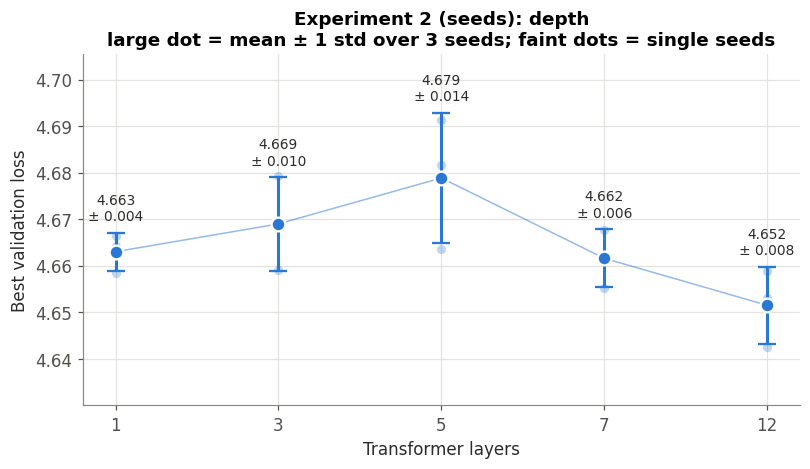

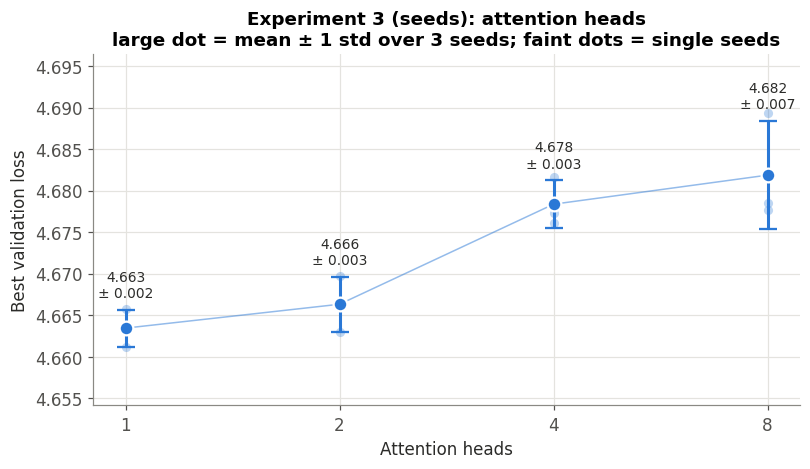

,layers,n_seeds,mean_best_val,std,min,max,per_seed,mean_best_epoch
0,1,3,4.6630,0.0041,4.6584,4.6663,"4.664, 4.658, 4.666",30.6667
1,3,3,4.6690,0.0101,4.6592,4.6793,"4.679, 4.669, 4.659",28.6667
2,5,3,4.6789,0.0140,4.6637,4.6913,"4.691, 4.682, 4.664",28.3333
3,7,3,4.6616,0.0063,4.6551,4.6676,"4.668, 4.655, 4.662",27.6667
4,12,3,4.6515,0.0083,4.6426,4.6590,"4.653, 4.659, 4.643",29.0000


,heads,n_seeds,mean_best_val,std,min,max,per_seed,mean_best_epoch
0,1,3,4.6635,0.0022,4.6612,4.6657,"4.666, 4.663, 4.661",28.3333
1,2,3,4.6663,0.0033,4.6630,4.6697,"4.666, 4.670, 4.663",28.0000
2,4,3,4.6784,0.0029,4.6761,4.6817,"4.676, 4.677, 4.682",26.6667
3,8,3,4.6819,0.0065,4.6777,4.6894,"4.689, 4.678, 4.679",26.6667


Layers: best-vs-worst difference in mean = 0.027, typical seed std = 0.009  =>  larger than the seed noise -> probably a real effect
Heads: best-vs-worst difference in mean = 0.018, typical seed std = 0.004  =>  larger than the seed noise -> probably a real effect


In [26]:
SEEDS = [_DEFAULT_SEED, 42, 7]     # first = original seed (cached); the others are trained

seed_runs = {"layers": {L: [] for L in EXP2_LAYERS}, "heads": {h: [] for h in EXP3_HEADS}}
for s in SEEDS:
    print(f"\n=== seed {s} ===")
    for L in EXP2_LAYERS:
        seed_runs["layers"][L].append(run_with_seed(s, {**BASE_CFG, "n_layers": L}, FIXED_LR, FIXED_EPOCHS,
                                                    label=f"{L} layers, seed {s}"))
    for h in EXP3_HEADS:
        seed_runs["heads"][h].append(run_with_seed(s, {**BASE_CFG, "n_heads": h}, FIXED_LR, FIXED_EPOCHS,
                                                   label=f"{h} heads, seed {s}"))


def seed_stats(groups, setting):
    rows = []
    for x, runs in groups.items():
        v = np.array([r["best_val_loss"] for r in runs])
        rows.append({setting: x, "n_seeds": len(v), "mean_best_val": v.mean(),
                     "std": v.std(ddof=1) if len(v) > 1 else float("nan"),
                     "min": v.min(), "max": v.max(),
                     "per_seed": ", ".join(f"{a:.3f}" for a in v),
                     "mean_best_epoch": np.mean([r["best_epoch"] for r in runs])})
    return pd.DataFrame(rows).round(4)


def plot_seed_errorbars(groups, xlabel, title, name):
    xs = list(groups)
    means, stds = [], []
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    for i, x in enumerate(xs):
        v = np.array([r["best_val_loss"] for r in groups[x]])
        means.append(v.mean())
        stds.append(v.std(ddof=1) if len(v) > 1 else 0.0)
        ax.plot([i] * len(v), v, "o", color=SERIES[0], alpha=0.3, ms=6, mec="none")
    ax.plot(range(len(xs)), means, color=SERIES[0], lw=1, alpha=0.5)
    ax.errorbar(range(len(xs)), means, yerr=stds, fmt="o", color=SERIES[0], ms=9, mec="white",
                mew=1.5, capsize=6, lw=2)
    for i, (m, s) in enumerate(zip(means, stds)):
        ax.annotate(f"{m:.3f}\n± {s:.3f}", (i, m + s), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=9, color="#2b2b29")
    ax.set_xticks(range(len(xs)), [str(x) for x in xs])
    ax.set(xlabel=xlabel, ylabel="Best validation loss",
           title=title + f"\nlarge dot = mean ± 1 std over {len(SEEDS)} seeds; faint dots = single seeds")
    ax.margins(y=0.25)
    save_fig(fig, name)


t_layers = seed_stats(seed_runs["layers"], "layers")
t_heads = seed_stats(seed_runs["heads"], "heads")
plot_seed_errorbars(seed_runs["layers"], "Transformer layers", "Experiment 2 (seeds): depth", "exp2_seeds")
plot_seed_errorbars(seed_runs["heads"], "Attention heads", "Experiment 3 (seeds): attention heads", "exp3_seeds")
save_table(t_layers, "exp2_seeds_summary")
save_table(t_heads, "exp3_seeds_summary")

# Rough rule of thumb: a difference smaller than ~2 standard deviations is not clearly real.
for what, t in (("Layers", t_layers), ("Heads", t_heads)):
    spread = t["mean_best_val"].max() - t["mean_best_val"].min()
    noise = t["std"].mean()
    verdict = ("larger than the seed noise -> probably a real effect" if spread > 2 * noise
               else "within ~2x the seed noise -> not clearly a real effect")
    print(f"{what}: best-vs-worst difference in mean = {spread:.3f}, typical seed std = {noise:.3f}  =>  {verdict}")
finish_cell()

## 11.3 — Corrected tables & figures, updated master table, zip
* Every earlier table is saved again with the learning rate shown correctly (`1e-04` instead of `0.0`) and a `seed` column. File names are unchanged, so the old versions are overwritten.
* The Experiment 1 grid is redrawn without the stray "epoch 6" column (a leftover from quick mode).
* The gradient-norm plots are redrawn with plain numbers on the log axis.
* The master table and the zip now include the Phase 11 runs.

,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Baseline,28.954,4e-04,123,20,4.616,10,101.045,2.473,4.973,2.5,1.392,False


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,lr = 0.0001,28.954,1e-04,123,500,4.676,25,107.344,0.006,9.973,9.967,36.228,False
1,lr = 0.001,28.954,1e-03,123,500,4.809,14,122.662,0.009,9.645,9.635,35.833,False
2,lr = 0.01,28.954,1e-02,123,500,4.951,53,141.364,0.113,8.588,8.475,35.719,False


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged,layers
0,1 layer,26.587,1e-04,123,38,4.664,30,106.096,3.369,4.694,1.325,2.430,False,1
1,3 layers,28.165,1e-04,123,38,4.679,25,107.693,3.337,4.740,1.403,2.642,False,3
2,5 layers,29.743,1e-04,123,38,4.691,30,108.998,3.311,4.753,1.441,2.839,False,5
3,7 layers,31.321,1e-04,123,38,4.668,29,106.444,3.308,4.699,1.391,3.025,False,7
4,12 layers,35.266,1e-04,123,38,4.653,29,104.896,3.335,4.696,1.361,3.528,False,12


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged,heads,head_dim
0,1 head (head dim 256),28.954,1e-04,123,38,4.666,29,106.241,3.271,4.738,1.467,2.794,False,1,256
1,2 heads (head dim 128),28.954,1e-04,123,38,4.666,29,106.299,3.278,4.730,1.452,2.746,False,2,128
2,4 heads (head dim 64),28.954,1e-04,123,38,4.676,25,107.352,3.299,4.741,1.442,2.752,False,4,64
3,8 heads (head dim 32),28.954,1e-04,123,38,4.689,25,108.785,3.306,4.754,1.448,2.774,False,8,32


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Full model (reference),28.954,1e-04,123,38,4.676,25,107.352,3.299,4.741,1.442,2.752,False
1,No LayerNorm,28.950,1e-04,123,38,4.627,37,102.206,3.710,4.630,0.919,2.705,False
2,No shortcut,28.954,1e-04,123,38,5.564,38,260.903,5.281,5.564,0.283,2.726,False
3,No FFN,26.849,1e-04,123,38,4.747,37,115.182,3.751,4.748,0.997,2.548,False


,run,params_M,lr,seed,epochs,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Full model (reference) [12 layers],35.266,1e-04,123,38,4.653,29,104.896,3.335,4.696,1.361,3.528,False
1,No LayerNorm [12 layers],35.253,1e-04,123,38,4.613,37,100.758,3.799,4.616,0.817,3.411,False
2,No shortcut [12 layers],35.266,1e-04,123,38,6.316,11,553.309,6.274,6.342,0.068,3.398,False
3,No FFN [12 layers],28.953,1e-04,123,38,4.824,37,124.509,4.047,4.831,0.783,2.933,False


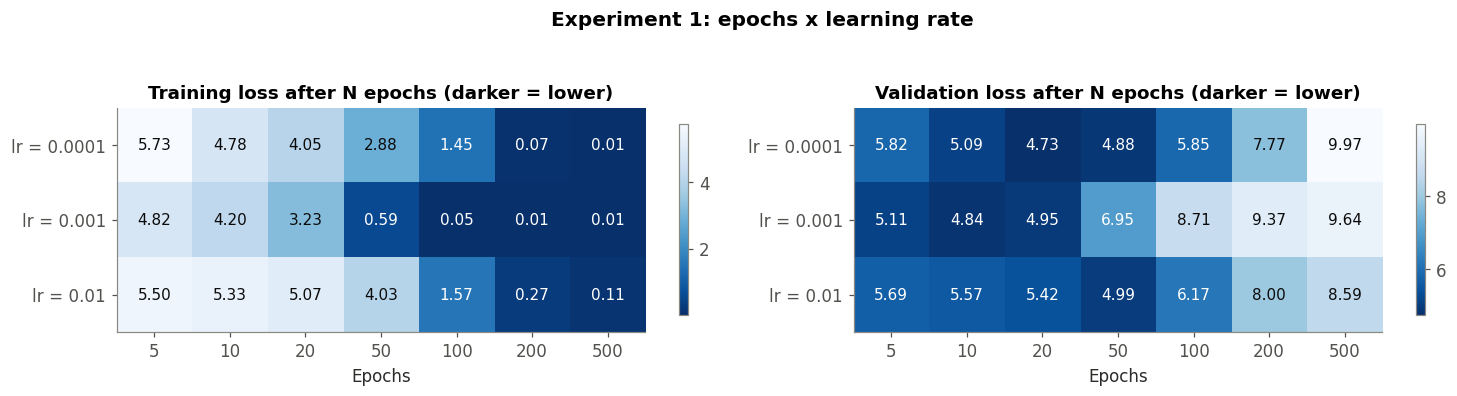

,lr,val@5,val@10,val@20,val@50,val@100,val@200,val@500
0,lr = 0.0001,5.825,5.091,4.734,4.885,5.848,7.771,9.973
1,lr = 0.001,5.113,4.843,4.945,6.952,8.707,9.375,9.645
2,lr = 0.01,5.688,5.566,5.418,4.992,6.174,8.000,8.588


,lr,train@5,train@10,train@20,train@50,train@100,train@200,train@500
0,lr = 0.0001,5.732,4.776,4.048,2.883,1.447,0.067,0.006
1,lr = 0.001,4.822,4.200,3.230,0.586,0.048,0.014,0.009
2,lr = 0.01,5.497,5.331,5.070,4.026,1.572,0.272,0.113


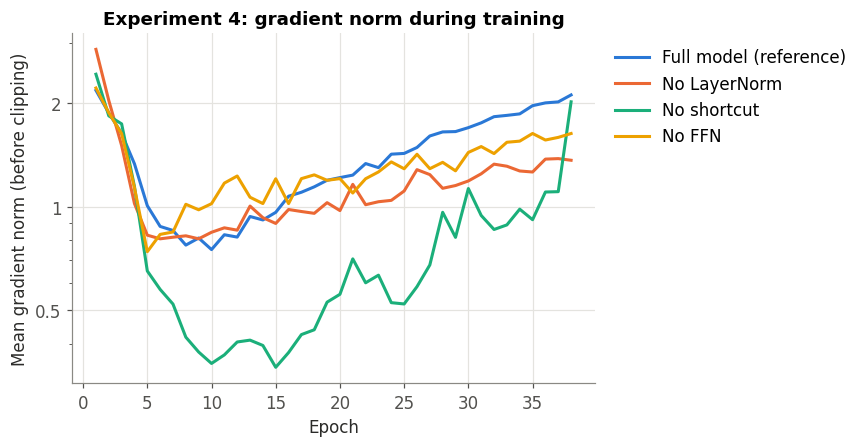

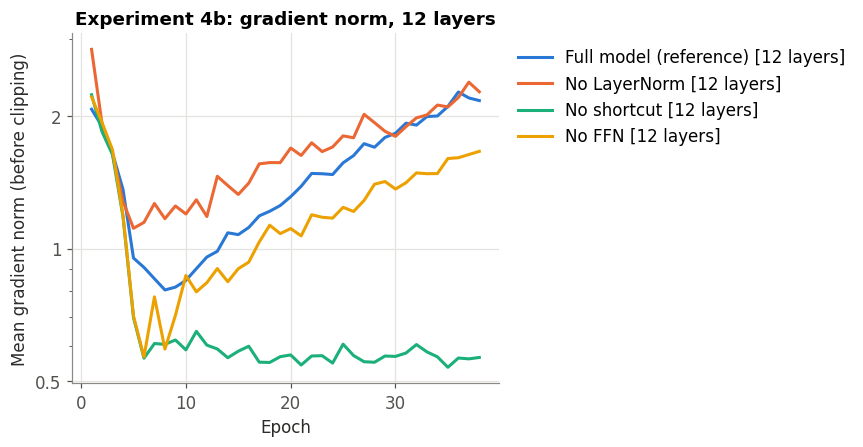

,experiment,run,layers,heads,lr,seed,epochs,params_M,best_val,best_epoch,best_val_ppl,final_train,final_val,gap,min_per_run,diverged
0,Baseline,Baseline,4,4,4e-04,123,20,28.954,4.616,10,101.045,2.473,4.973,2.500,1.392,False
1,Exp1 LR x epochs,lr = 0.0001,4,4,1e-04,123,500,28.954,4.676,25,107.344,0.006,9.973,9.967,36.228,False
2,Exp1 LR x epochs,lr = 0.001,4,4,1e-03,123,500,28.954,4.809,14,122.662,0.009,9.645,9.635,35.833,False
3,Exp1 LR x epochs,lr = 0.01,4,4,1e-02,123,500,28.954,4.951,53,141.364,0.113,8.588,8.475,35.719,False
4,Exp2 layers,1 layer,1,4,1e-04,123,38,26.587,4.664,30,106.096,3.369,4.694,1.325,2.430,False
5,Exp2 layers,3 layers,3,4,1e-04,123,38,28.165,4.679,25,107.693,3.337,4.740,1.403,2.642,False
6,Exp2 layers,5 layers,5,4,1e-04,123,38,29.743,4.691,30,108.998,3.311,4.753,1.441,2.839,False
7,Exp2 layers,7 layers,7,4,1e-04,123,38,31.321,4.668,29,106.444,3.308,4.699,1.391,3.025,False
8,Exp2 layers,12 layers,12,4,1e-04,123,38,35.266,4.653,29,104.896,3.335,4.696,1.361,3.528,False
9,Exp3 heads,1 head (head dim 256),4,1,1e-04,123,38,28.954,4.666,29,106.241,3.271,4.738,1.467,2.794,False


Archive: /content/drive/MyDrive/LLM_Scratch_Assignment/report_assets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
# 1) earlier tables with the learning rate displayed correctly
save_table(summary_table([baseline]), "baseline_summary")
save_table(summary_table(exp1), "exp1_summary")
save_table(summary_table(exp2, lambda r: {"layers": r["cfg"]["n_layers"]}), "exp2_summary")
save_table(summary_table(exp3, lambda r: {"heads": r["cfg"]["n_heads"],
                                          "head_dim": r["cfg"]["emb_dim"] // r["cfg"]["n_heads"]}), "exp3_summary")
save_table(summary_table(exp4), "exp4_summary")
if exp4_deep:
    save_table(summary_table(exp4_deep), "exp4b_summary")

# 2) Exp 1 grid without the stray epoch-6 column
shown = [e for e in EXP1_CHECKPOINTS if QUICK_MODE or e != 6]
grids = {k: pd.DataFrame({e: [loss_at(r, e, k) for r in exp1] for e in shown}, index=[r["label"] for r in exp1])
         for k in ("train_loss", "val_loss")}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
for ax, (k, grid), t in zip(axes, grids.items(), ("Training loss", "Validation loss")):
    vals = grid.values.astype(float)
    im = ax.imshow(vals, cmap="Blues_r", aspect="auto")
    lo, hi = np.nanmin(vals), np.nanmax(vals)
    for (i, j), v in np.ndenumerate(vals):
        dark = (v - lo) / (hi - lo + 1e-9) < 0.45 if np.isfinite(v) else False
        ax.text(j, i, "-" if not np.isfinite(v) else f"{v:.2f}", ha="center", va="center",
                fontsize=10, color="white" if dark else "#0b0b0b")
    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set(xlabel="Epochs", title=t + " after N epochs (darker = lower)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle("Experiment 1: epochs x learning rate", fontweight="bold", y=1.05)
save_fig(fig, "exp1_grid")
for k, short in (("val_loss", "val"), ("train_loss", "train")):
    g = grids[k].copy()
    g.columns = [f"{short}@{c}" for c in g.columns]
    save_table(g.reset_index(names="lr").round(3), f"exp1_{short}_grid")

# 3) gradient-norm plots with plain numbers on the log axis
plot_metric(exp4, "grad_norm", "Mean gradient norm (before clipping)",
            "Experiment 4: gradient norm during training", "exp4_grad_norm", logy=True)
if exp4_deep:
    plot_metric(exp4_deep, "grad_norm", "Mean gradient norm (before clipping)",
                "Experiment 4b: gradient norm, 12 layers", "exp4b_grad_norm", logy=True)

# 4) master table including Phase 11
groups = [("Baseline", [baseline]), ("Exp1 LR x epochs", exp1), ("Exp2 layers", exp2), ("Exp3 heads", exp3),
          ("Exp4 ablations", exp4), ("Exp4b deep ablations", exp4_deep)]
groups += [(f"Exp4c ablations lr {fmt_lr(ABL_LR)}", abl_hi[L]) for L in ABL_DEPTHS]
groups += [(f"Seeds {what}", [r for runs in seed_runs[what].values() for r in runs
                              if r.get("seed", _DEFAULT_SEED) != _DEFAULT_SEED]) for what in ("layers", "heads")]
master = pd.concat([summary_table(runs, lambda r, g=g: {"experiment": g, "layers": r["cfg"]["n_layers"],
                                                        "heads": r["cfg"]["n_heads"]})
                    for g, runs in groups if runs], ignore_index=True)
master = master[["experiment", "run", "layers", "heads", "lr", "seed", "epochs", "params_M", "best_val",
                 "best_epoch", "best_val_ppl", "final_train", "final_val", "gap", "min_per_run", "diverged"]]
save_table(master, "master_results")

# 5) generated text of the new ablation runs
with open(os.path.join(TAB_DIR, f"{RUN_PREFIX}generated_samples_phase11.md"), "w", encoding="utf-8") as f:
    f.write(f"# Phase 11 samples (prompt: {PROMPT!r})\n\n")
    for L in ABL_DEPTHS:
        for r in abl_hi[L]:
            f.write(f"## {r['label']} [{L} layers, lr {fmt_lr(ABL_LR)}] (best epoch {r['best_epoch']})\n\n"
                    f"{r['final_sample']}\n\n")

# 6) zip of all figures + tables, then download
import zipfile
archive = os.path.join(SAVE_DIR, f"{RUN_PREFIX}report_assets.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ("figures", "tables"):
        for fn in sorted(os.listdir(os.path.join(SAVE_DIR, sub))):
            if fn.startswith(RUN_PREFIX) or fn == "dataset_stats.json":
                z.write(os.path.join(SAVE_DIR, sub, fn), arcname=f"{sub}/{fn}")
print("Archive:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)
finish_cell()

### New outputs for the report
| Section | Figures | Tables |
|---|---|---|
| Exp 4c: ablations at lr 1e-3 | `exp4c_L4_*`, `exp4c_L12_*` (losses, gradient norm, best-loss dots) | `exp4c_L*_summary`, `exp4c_low_vs_high_lr` |
| Exp 2 with seeds | `exp2_seeds` | `exp2_seeds_summary` |
| Exp 3 with seeds | `exp3_seeds` | `exp3_seeds_summary` |
| Everything | – | `master_results` (now with `lr` and `seed` columns) |